<a href="https://colab.research.google.com/github/juanjosemfranchi-netizen/educacion_escolaridad/blob/main/TRABAJO_APREN_AUTOMATICO_completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏫 Segmentación de Establecimientos Educativos y su Relación con Indicadores de Trayectoria Escolar

## 📌 Contexto y Definición del Problema
En el sistema educativo argentino existen marcadas disparidades en la disponibilidad de infraestructura, servicios básicos y equipamiento tecnológico. Esta heterogeneidad impacta de manera directa en las dinámicas pedagógicas y en el entorno de aprendizaje de los estudiantes.

**El Desafío:**  
Actualmente resulta complejo identificar objetivamente cuales son las condiciones que ayudan al crecimiento de en la tasa de repitencia de los alumnos, con este trabajo, creemos que es posible determinar si la infraesctructura de los establecimientos ayuda a que esta variable crezca significativamente, producienco un impacto en los alumnos y en su rendimiento escolar basandonos en las tasas de **abandono**, **promoción efectiva** y **repitencia**.

---

## 🎯 Objetivos del Proyecto

* **Objetivo General:** Predecir la tasa de depitencia en instituciones educativas de la República Argentina utilizando técnicas de aprendizaje no supervisado (**Regresion Lineal**) sobre variables de infraestructura, conectividad y trayectoria escolar. 
* **Objetivos Específicos:**
  1. Integrar y limpiar los datos de infraestructura escolar con los registros de indicadores educativos a través de la clave única institucional (`provincia x departamento x sector x ambito`).
  2. Construir índices y preprocesar las variables tecnológicas, de energía y de conectividad (escalado y reducción de dimensionalidad).
  3. Realizar un analisis exploratorio de datos (EDA) para caracterizar los perfiles de intraestructura agrupados segun provincia x departamento x sector x ambito, y ver si poseen relaciones con las tasas de repitencia en el dataset de matriculas. 
  5. Aplicar algoritmos de regresion lineal (ej. *Linea Regresion*) para encontrar patrones de relacion que permitan relacionar datos de infraestructura con datos de trayectoria escolar.

---

## 📂 Repositorio Oficial del Proyecto
Todo el desarrollo, scripts de preprocesamiento, análisis exploratorio y datasets crudos se encuentran centralizados en el siguiente repositorio de GitHub:
👉 **[(REPO) educacion_escolaridad](https://github.com/juanjosemfranchi-netizen/educacion_escolaridad)**

---

## 📊 Fuente y Dataset Utilizado

Los conjuntos de datos provienen del portal de Datos Abiertos (`datos.gob.ar`) y han sido alojados dentro del repositorio en la carpeta `/datasets_crudos/`:

######  **Características e Infraestructura de Establecimientos (2025):**
   * **Archivo:** `2024 Caracteristicas - agregada.xlsx` ([Ver en GitHub]https://github.com/juanjosemfranchi-netizen/educacion_escolaridad/blob/main/datasets_crudos/2024%20Matricula%20-%20agregada.xlsx)  
   * *Variables clave:* Localización (`provincia`, `departamento`, `sector`, `ambito`), fuentes de energía (red pública, solar, generador), conectividad a internet en aulas/laboratorios, equipamiento tecnológico (proyectores, PCs, pizarras digitales, impresoras) y uso de sistemas de gestión.

   * **Archvo:** `2024 Matricula - Agregada.xlsx` ([Ver en Github]https://github.com/juanjosemfranchi-netizen/educacion_escolaridad/blob/main/datasets_crudos/2024%20Matricula%20-%20agregada.xlsx)
   * *Variables clave:* 
---

---
# 1. 📌 Introducción

*Punto 1 de la entrega.*

El contexto, el problema y los objetivos están desarrollados en la portada.



Los **beneficios esperados**: esperamos que con esta informacion tanto las instituciones educativas como las entidades gubernamentales puedan tomar accion y conciencia sobre las necesidades de los alumnos para manterner un aprendizaje consistente y reducir asi la tasa de repitencia.


---
# 2. 📊 Fuentes y conjuntos de datos


## 2.1 Las tres bases utilizadas

Las tres salen del mismo **Relevamiento Anual 2025** del Ministerio de Capital Humano, publicadas en el
[Buscador de bases usuarias](https://www.argentina.gob.ar/educacion/evaluacion-e-informacion-educativa/datos-abiertos-de-la-secretaria-de-educacion).
Por venir del mismo relevamiento comparten la misma clave, que es lo que permite integrarlas.

| Base | Qué aporta | Filas |
|---|---|---|
| `2025 Caracteristicas - agregada.csv` | infraestructura, equipamiento, conectividad | 1217 |
| `2025 Matricula - agregada.csv` | matrícula, repitentes, sobreedad por año de estudio | 1217 |
| `2025 Trayectoria - agregada.csv` | salidos sin pase, promovidos, no promovidos, egresados | 1210 |

**Clave de integración:** `provincia × departamento × sector × ámbito`

>Se usa además el archivo oficial `Tasa de Repitencia 2023-2012 según división político-territorial.xlsx`
>para tomar la estructura educativa (6-6 o 7-5) de cada provincia y para validar el cálculo
>departamental contra la cifra publicada.


## Indice y Diccionario de Variables (En Crudo)

A continuación se detalla la semántica y el significado de cada campo de las tres bases del Relevamiento Anual 2025:

### **Características e Infraestructura** 

#### Ubicación y Contexto Institucional
* **`provincia`**: Nombre de la provincia o jurisdicción donde reside el establecimiento.
* **`departamento`**: Departamento o partido correspondiente dentro de la provincia.
* **`sector`**: Gestión del establecimiento (*Estatal* / *Privado*).
* **`ambito`**: Entorno geográfico del establecimiento (*Urbano* / *Rural*).
* **`Localizacion`**: Cantidad de establecimientos que componen el grupo. Va de 1 a 704 y suma 50.588 en todo el país.



#### Provisión de Energía Eléctrica
* **`ElectricidadSi`**: Indicador de si el establecimiento cuenta con acceso a electricidad.
* **`ElectricidadRedpública`**: Conexión a la red pública de distribución eléctrica.
* **`ElectricidadGrupoelectrógeno`**: Disponibilidad de grupo electrógeno.
* **`ElectricidadPanelfotovoltaicosolar`**: Provisión mediante paneles solares.
* **`ElectricidadGeneradoreólico`**: Provisión mediante generadores eólicos.
* **`ElectricidadGeneradorhidráulico`**: Provisión mediante mini-turbinas/generadores hidráulicos.
* **`ElectricidadOtro`**: Otras fuentes alternativas de energía eléctrica.



#### Equipamiento Tecnológico Institucional (Uso General)
*(Son conteos de aparatos, no indicadores sí/no: un departamento llega a 39,8 televisores por establecimiento.)*
* **`EquipamientoEstablecimientoTelevisor`**: Disponibilidad de televisores en el establecimiento.
* **`EquipamientoEstablecimientoSistemamultimediaoCañón`**: Proyectores o cañones multimedia.
* **`EquipamientoEstablecimientoScanner`**: Escáneres para digitalización de documentos.
* **`EquipamientoEstablecimientoWebcam`**: Cámaras web disponibles para actividades institucionales/aúlicas.
* **`EquipamientoEstablecimientoTeléfonointeligente`**: Teléfonos inteligentes institucionales.
* **`EquipamientoEstablecimientoImpresora`**: Impresoras en el establecimiento.
* **`EquipamientoEstablecimientoEquipoemisorderadioAMFM`**: Transmisor de radio AM/FM propio.
* **`EquipamientoEstablecimientoEquiporeceptorderadioAMFM`**: Receptor/radio AM/FM.
* **`EquipamientoEstablecimientoServidorparausoescolar`**: Servidor dedicado para red local o gestión pedagógica.
* **`EquipamientoEstablecimientoImpresora3D`**: Disponibilidad de impresoras 3D.
* **`EquipamientoEstablecimientoEquipodeSonido`**: Equipos de audio y amplificación.
* **`EquipamientoEstablecimientoPizarrasdigitales`**: Pizarras o pantallas digitales interactivas.



#### Equipamiento Específico en Biblioteca
*(Inventario tecnológico ubicado exclusivamente dentro del espacio de la biblioteca. Acá conviven dos tipos: Televisor, Multimedia, Webcam, Impresora, Servidor, Equipo de Sonido y Pizarras digitales son conteos de aparatos (hasta 3,8 por escuela); Scanner, Teléfono inteligente, Emisor AM/FM, Receptor AM/FM e Impresora 3D cuentan establecimientos y nunca superan 1,0.)*
* **`EquipamientoBibliotecaTelevisor`**, **`EquipamientoBibliotecaSistemamultimediaoCañón`**, **`EquipamientoBibliotecaScanner`**, **`EquipamientoBibliotecaWebcam`**, **`EquipamientoBibliotecaTeléfonointeligente`**, **`EquipamientoBibliotecaImpresora`**, **`EquipamientoBibliotecaEquipoemisorderadioAMFM`**, **`EquipamientoBibliotecaEquiporeceptorderadioAMFM`**, **`EquipamientoBibliotecaServidorparausoescolar`**, **`EquipamientoBibliotecaImpresora3D`**, **`EquipamientoBibliotecaEquipodeSonido`**, **`EquipamientoBibliotecaPizarrasdigitales`**.



#### Conectividad a Internet
* **Financiamiento:**
  * **`InternetTipodeservicioGratuito`**: Servicio provisto de forma gratuita (ej. programas estatales).
  * **`InternetTipodeservicioGratuitoOtro`**: Otro esquema de gratuidad.
  * **`InternetTipodeservicioPago`**: Servicio abonado por la institución o cooperadora.
* **Tecnología de Conexión:**
  * **`InternetTipodeconexiónTelefónica`**, **`InternetTipodeconexiónADSL`**, **`InternetTipodeconexiónCableMódem`**, **`InternetTipodeconexiónSatelital`**, **`InternetTipodeconexiónMóvil`**, **`InternetTipodeconexiónOtroTipo`**.
* **Cobertura por Espacios Físicos:**
  * **`EspaciosconconexiónEneláreadeadministración`**: Cobertura en oficinas administrativas.
  * **`EspaciosconconexiónEnlasaulas`**: Cobertura dentro de las aulas pedagógicas.
  * **`EspaciosconconexiónEnlabibliotecas`**: Cobertura dentro de la biblioteca.
  * **`EspaciosconconexiónEnellaboratorio`**: Cobertura en laboratorio o sala informática.
  * **`EspaciosconconexiónEnotroespaciodelestablecimiento`**: Cobertura en patios o espacios comunes.



#### Infraestructura Física y Gestión Institucional
* **Sistemas de Gestión Escolar:**
  * **`SistemadeGestiónEscolarSi`**: Uso de software/plataforma de gestión escolar.
  * **`SistemadeGestiónEscolarProvistoporelMinisterio`**: Software provisto por el Ministerio.
  * **`SistemadeGestiónEscolarDesarrolladoporterceros`**: Software comercial o privado.
  * **`SistemadeGestiónEscolarEncargadoporelEstablecimiento`**: Sistema a medida encargado por la escuela.
  * **`SistemadeGestiónEscolarPlanilladeCalculo`**: Gestión realizada mediante planillas (Excel/Google Sheets).
* **Espacios Especializados:**
  * **`DisponedesalaolaboratoriodeinformáticaSi`**: Disponibilidad de sala/laboratorio de informática.
  * **`LaboratorioFuncionaesespacioexclusivoSi`**: El laboratorio es de uso exclusivo (no aula común).
  * **`BibliotecaDisponedealmenosunaSi`**: Disponibilidad de espacio físico de biblioteca.
  * **`BibliotecaFuncionaesespacioexclusivoSi`**: La biblioteca funciona en un espacio exclusivo.
* **Organización Social:**
  * **`CooperadoraConpersoneríajurídica`**: Cooperadora formalizada legalmente.
  * **`CooperadoraSinpersoneríajurídica`**: Cooperadora en funcionamiento sin personería.
  * **`CooperadoraNo`**: Ausencia de cooperadora escolar.
* **Aporte Estatal:**
  * **`SubvenciónEstatalJardínMaternalSi`**, **`SubvenciónEstatalJardíndeInfantesSi`**, **`SubvenciónEstatalPrimariaSi`**, **`SubvenciónEstatalSecundariaSi`**, **`SubvenciónEstatalSNUSi`**: Subvención estatal asignada por nivel educativo.


  ---

### **Matrícula**



#### Base de Matrícula
*(Composición de la matrícula por año de estudio. Los nombres son siglas; entre paréntesis, cómo se
verificó cada significado contra el propio dato.)*

* **`_1` … `_12`**: Matrícula por año de estudio, de 1° a 12°. *(suman 8.597.492 alumnos)*
* **`_1314`, `_20`, `_snu`**: Años 13°/14°, categoría 20 y Superior No Universitario. *(74.806 / 9.112 / 966.742)*
* **`lactantes`, `deambulantes`, `s2` … `s5`**: Salas del nivel inicial, de lactantes a sala de 5. *(1.484.126 alumnos)*
* **`v_…`**: Varones. *(50,5 % del total)*
* **`r_…`**: Repitentes. *(agregado a nivel provincia da r = 0,98 contra la tasa oficial del Ministerio)*
* **`s_…`**: Alumnos con sobreedad. *(21,3 % en secundaria, consistente con la cifra nacional)*
* **`_sec…`**: Secciones, es decir divisiones, no alumnos. *(443.142 secciones)*
* **`multi_ini`, `multi_pri`, `multi_sec`, `multinivel`**: Secciones multigrado y multinivel. *(32.475)*

> El prefijo `s` se usa para dos cosas distintas: `s2`…`s5` son las **salas** del nivel inicial,
> `s_1`…`s_12` es la **sobreedad** por año de estudio, y `s_s2`…`s_s5` es la sobreedad dentro de las salas.

---

### **Trayectoria** 

#### Base de Trayectoria
*(Qué pasó con cada alumno a lo largo del ciclo lectivo.)*

* **`inicial_…`**: Matrícula al inicio del ciclo. *(8.651.276)*
* **`entrados_…`**: Alumnos incorporados durante el ciclo. *(2,5 % de la inicial)*
* **`ssp_…`**: Salidos sin pase: dejan la escuela sin certificado de traslado. *(0,7 %)*
* **`scp_…`**: Salidos con pase: se transfieren a otro establecimiento. *(2,8 %)*
* **`ultimo_…`**: Matrícula al final del ciclo. No es «último año». *(99,1 % de la inicial)*
* **`promovidos_…`**: Promovidos directamente. *(82,6 % de la matrícula final)*
* **`promovidos_ex_…`**: Promovidos rindiendo examen. *(7,3 %)*
* **`promovidos_mas_2mat_…`**: Promovidos adeudando más de dos materias. *(4,2 %)*
* **`nopromo_…`**: No promovidos. *(6,0 %)*
* **`primaria_egresados`, `secundaria_egresados`**: Egresados del nivel. Columna única, sin año. *(730.192 y 461.612)*
* **`m_…`**: Mujeres. Se antepone a cualquiera de los anteriores. *(49,5 %, complementario de `v_`)*


**Las dos identidades que validan la lectura de esta base:**

```
inicial + entrados − salidos sin pase − salidos con pase = último
promovidos + promovidos_ex + promovidos_mas_2mat + no promovidos = último
```

La primera se cumple en el 100,0 % de las filas y confirma que `inicial` y `ultimo` son los dos extremos
del ciclo. La segunda también cierra al 100,0 %, con diferencia mediana de 0 alumnos, y muestra que las
cuatro categorías de promoción son excluyentes entre sí: `promovidos_ex` y `promovidos_mas_2mat` **no**
están incluidas dentro de `promovidos`, van aparte.

---
# 3. ⚙️ Carga de los datos


## 3.1 Librerías


In [2]:
import os, re, json, unicodedata, urllib.request, urllib.parse, warnings
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 3.2 Carga de los tres datasets


In [3]:

warnings.filterwarnings("ignore")

BASE = "https://raw.githubusercontent.com/juanjosemfranchi-netizen/educacion_escolaridad"
# Se prueba primero main; la rama queda como respaldo mientras el PR no esté mergeado.
REFS = ["main", "agrego-datasets"]
ARCHIVOS = {
    "caracteristicas": "2024%20Caracteristicas%20-%20agregada.xlsx",
    "matricula":       "2024%20Matricula%20-%20agregada.xlsx",
    "trayectoria":     "2024%20Trayectoria%20-%20agregada.xlsx",
    "repitencia_ofi":  "Tasa%20de%20Repitencia%202023-2012%20seg%C3%BAn%20divisi%C3%B3n%20pol%C3%ADtico-territorial.xlsx",
}
os.makedirs("data", exist_ok=True)
RUTAS, FALTAN = {}, []
for k, v in ARCHIVOS.items():
    destino = os.path.join("data", f"{k}.xlsx")
    if not os.path.exists(destino):
        for ref in REFS:
            try:
                urllib.request.urlretrieve(f"{BASE}/{ref}/datasets_crudos/{v}", destino)
                break
            except Exception:
                continue
        else:
            FALTAN.append((k, urllib.parse.unquote(v)))
            continue
    RUTAS[k] = destino

if FALTAN:
    msg = ["No se pudieron obtener estas bases desde el repositorio:", ""]
    for k, nombre in FALTAN:
        msg.append(f"   - {nombre}")
    msg += ["",
            "Hay que subirlas a la carpeta datasets_crudos/ del repositorio.",
            "Se descargan del Buscador de bases usuarias del Ministerio de Capital Humano:",
            "https://www.argentina.gob.ar/educacion/evaluacion-e-informacion-educativa/"
            "datos-abiertos-de-la-secretaria-de-educacion",
            "",
            "Alternativa sin tocar el repo: subirlas a mano a la carpeta data/ de esta",
            "sesion de Colab, con estos nombres exactos:",
            ] + [f"   data/{k}.xlsx" for k, _ in FALTAN]
    raise FileNotFoundError("\n".join(msg))

print(f"Las {len(RUTAS)} bases se cargaron correctamente:")
for k, r in RUTAS.items():
    print(f"   {k:<18} {os.path.getsize(r)/1024:>8,.0f} KB")

IDS = ["provincia", "departamento", "sector", "ambito"]

def norm(s):
    s = unicodedata.normalize("NFKD", str(s).strip()).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper()

def leer(ruta):
    d = pd.read_excel(ruta, engine='openpyxl', dtype=str)

    d.columns = (
        d.columns
        .astype(str)
        .str.strip()
        .str.lower()
    )

    for c in IDS:
        d[c] = d[c].str.strip()
    return d

car = leer(RUTAS["caracteristicas"])
mat = leer(RUTAS["matricula"])
tra = leer(RUTAS["trayectoria"])

for n, d in [("Caracteristicas", car), ("Matricula", mat), ("Trayectoria", tra)]:
    print(f"{n:<16} {d.shape[0]:>5} filas x {d.shape[1]:>3} columnas | clave unica: {not d.duplicated(IDS).any()}")


Las 4 bases se cargaron correctamente:
   caracteristicas         351 KB
   matricula               588 KB
   trayectoria           1,532 KB
   repitencia_ofi          114 KB
Caracteristicas   1216 filas x  66 columnas | clave unica: True
Matricula         1216 filas x 104 columnas | clave unica: True
Trayectoria       1209 filas x 288 columnas | clave unica: True


## 3.2 Visualizacion del dataset de características

In [4]:
df_caracteristicas = car.copy()
print("=== INFORMACIÓN DEL DATASET CRUDO ===")
print(f"• Total de filas (provincia x departamento x sector x ambito x localidad): {df_caracteristicas.shape[0]:,}")
print(f"• Total de columnas (variables): {df_caracteristicas.shape[1]}")


pd.set_option('display.max_columns', None)

df_caracteristicas.head(10)

=== INFORMACIÓN DEL DATASET CRUDO ===
• Total de filas (provincia x departamento x sector x ambito x localidad): 1,216
• Total de columnas (variables): 66


,provincia,departamento,sector,ambito,localizacion,electricidadsi,electricidadredpública,electricidadgrupoelectrógeno,electricidadpanelfotovoltaicosolar,electricidadgeneradoreólico,electricidadgeneradorhidráulico,electricidadotro,equipamientoestablecimientotelevisor,equipamientoestablecimientosistemamultimediaocañón,equipamientoestablecimientoscanner,equipamientoestablecimientowebcam,equipamientoestablecimientoreproductordecd,equipamientoestablecimientoreproductordedvd,equipamientoestablecimientoimpresora,equipamientoestablecimientoequipoemisorderadioamfm,equipamientoestablecimientoequiporeceptorderadioamfm,equipamientoestablecimientoservidorparausoescolar,equipamientoestablecimientoimpresora3d,equipamientoestablecimientoequipodesonido,equipamientoestablecimientopizarrasdigitales,equipamientobibliotecatelevisor,equipamientobibliotecasistemamultimediaocañón,equipamientobibliotecascanner,equipamientobibliotecaequipamientobibliotecawebcam,equipamientobibliotecareproductordecd,equipamientobibliotecareproductordedvd,equipamientobibliotecaimpresora,equipamientobibliotecaequipoemisorderadioamfm,equipamientobibliotecaequiporeceptorderadioamfm,equipamientobibliotecaservidorparausoescolar,internettipodeserviciogratuitoestado,internettipodeserviciogratuitootro,internettipodeserviciopago,internettipodeconexióntelefónica,internettipodeconexiónadsl,internettipodeconexióncablemódem,internettipodeconexiónsatelital,internettipodeconexiónotrotipo,internettipodeconexiónmóvil,espaciosconconexióneneláreadeadministración,espaciosconconexiónenlasaulas,espaciosconconexiónenlabibliotecas,espaciosconconexiónenotroespaciodelestablecimiento,espaciosconconexiónenellaboratorio,cooperadoraconpersoneríajurídica,cooperadorasinpersoneríajurídica,cooperadorano,sistemadegestiónescolarsi,sistemadegestiónescolarprovistoporelministerio,sistemadegestiónescolardesarrolladoporterceros,sistemadegestiónescolarencargadoporelestablecimiento,sistemadegestiónescolarplanilladecalculo,disponedesalaolaboratoriodeinformáticasi,laboratoriofuncionaesespacioexclusivosi,bibliotecadisponedealmenosunasi,bibliotecafuncionaesespacioexclusivosi,subvenciónestataljardínmaternalsi,subvenciónestataljardíndeinfantessi,subvenciónestatalprimariasi,subvenciónestatalsecundariasi,subvenciónestatalsnusi
0,Buenos Aires,25 DE MAYO,Estatal,Rural,49,49,48,3,,,,,34,35,19,9,15,17,41,14,,2,2,31,14,8,9,3,3,4,4,10,3,,1,41,6,1,1,2,12,31,6,4,28,44,13,22,3,31,12,6,17,15,,,2,10,6,25,14,,,,,
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,43,43,43,,,,,,30,28,23,6,14,13,31,20,,5,3,30,16,14,11,2,,1,3,2,,,2,34,1,8,2,2,22,15,5,2,35,35,21,21,8,23,6,14,15,15,,,,12,3,35,20,,,,,
2,Buenos Aires,25 DE MAYO,Privado,Urbano,9,9,9,,,,,,7,6,6,6,6,5,9,3,,5,,8,1,3,5,1,2,2,1,3,1,,2,,,9,1,,7,,,5,9,9,5,8,3,,,9,6,2,,3,1,4,1,6,4,,3,3,3,
3,Buenos Aires,9 DE JULIO,Estatal,Rural,50,50,50,,,,,,32,38,23,10,16,19,37,13,,8,3,31,18,15,16,6,2,5,7,8,2,,2,38,10,2,2,3,19,28,3,1,32,45,21,23,12,22,12,16,16,14,,,2,14,7,35,23,,,,,
4,Buenos Aires,9 DE JULIO,Estatal,Urbano,36,36,36,,,,,,21,30,17,11,11,12,32,12,,1,4,28,13,7,9,1,1,2,2,9,2,,,23,7,5,7,3,18,9,5,5,32,26,20,20,9,21,7,8,14,13,,1,,9,7,29,25,,,,,
5,Buenos Aires,9 DE JULIO,Privado,Urbano,8,8,8,,,,,,8,7,6,4,5,5,7,3,,2,,7,1,2,1,3,,1,2,1,1,,1,,,8,1,3,5,,,1,8,7,5,6,5,,,8,6,4,2,,,5,5,5,5,,2,2,3,
6,Buenos Aires,ADOLFO ALSINA,Estatal,Rural,27,26,26,,,,,,13,17,16,6,15,8,21,11,,2,,16,10,4,6,4,2,5,4,5,4,,1,22,4,,2,,6,18,3,1,19,24,10,11,3,13,7,7,11,11,,,,4,2,16,8,,,,,
7,Buenos Aires,ADOLFO ALSINA,Estatal,Urbano,18,18,18,1,,,,,18,16,11,5,9,8,18,10,,3,2,15,11,6,5,2,,2,1,3,2,,1,11,4,2,5,3,6,2,6,4,17,17,11,12,4,12,6,,12,10,,1,1,4,2,15,9,,,,,
8,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Rural,21,21,21,,1,,,,14,14,6,2,6,7,14,11,,4,1,10,7,4,5,1,,3,3,4,4,,1,18,2,1,4,,2,15,3,3,10,15,6,7,1,14,6,1,4,3,1,,,3,,13,6,,,,,
9,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Urbano,13,13,13,1,,,,,11,12,5,4,5,5,11,7,,2,1,10,7,7,6,,,2,2,3,3,,1,10,,2,2,2,3,3,2,3,11,10,10,8,5,11,2,,4,3,,,1,6,1,11,9,,,,,


Con las primeras visualizaciones del dataset de Caracteristicas, vemos que los registros no se desagregan por entidad educativa, sino que son un conjunto agregado de `provincia x departamento x ambito x localizacion`. 
El dataset tiene un total de 1216 registros (filas) por un total de 66 variables (columnas).
En una primera instancia se visualizan faltantes de datos que deberemos cotejar su implicancia en el caso de estudio cuando avancemos en el EDA.

## 3.2 Visualizacion del dataset de Matriculas

In [5]:
df_matriculas = mat.copy()
print("=== INFORMACIÓN DEL DATASET CRUDO ===")
print(f"• Total de filas (provincia x departamento x sector x ambito x localidad): {df_matriculas.shape[0]:,}")
print(f"• Total de columnas (variables): {df_matriculas.shape[1]}")


pd.set_option('display.max_columns', None)

df_matriculas.head(10)

=== INFORMACIÓN DEL DATASET CRUDO ===
• Total de filas (provincia x departamento x sector x ambito x localidad): 1,216
• Total de columnas (variables): 104


,provincia,departamento,sector,ambito,localizacion,lactantes,deambulantes,s2,s3,s4,s5,_1,_2,_3,_4,_5,_6,_7,_8,_9,_10,_11,_12,_1314,_20,_snu,v_lactantes,v_deambulantes,v_s2,v_s3,v_s4,v_s5,v_1,v_2,v_3,v_4,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_1314,v_20,v_snu,r_1,r_2,r_3,r_4,r_5,r_6,r_7,r_8,r_9,r_10,r_11,r_12,r_1314,r_20,s_lactantes,s_deambulantes,s_s2,s_s3,s_s4,s_s5,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_1314,_seclactantes,_secdeambu,_secs2,_secs3,_secs4,_secs5,_sec1,_sec2,_sec3,_sec4,_sec5,_sec6,_sec7,_sec8,_sec9,_sec10,_sec11,_sec12,_sec1314,_sec20,multi_ini,multi_pri,multi_sec,multinivel
0,Buenos Aires,25 DE MAYO,Estatal,Rural,49,,,51,50,60,64,82,106,90,94,96,101,119,121,114,115,108,88,,,,,,16,24,34,38,39,55,50,55,52,61,61,63,60,68,58,56,,,,0,3,5,6,1,1,2,9,11,5,5,0,,,,,,,,,2,4,7,7,4,5,18,20,20,12,18,7,,0,0,3,2,5,2,5,4,4,7,5,5,7,7,6,7,7,7,0,0,12,31,,0
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,43,33,105,274,303,280,352,316,318,330,360,315,319,397,381,371,358,310,278,33,,734,18,51,147,162,151,175,164,179,152,184,158,160,209,202,176,175,142,138,24,,163,0,19,12,7,13,15,51,53,44,60,45,2,0,,,,,,,,1,19,14,8,13,15,134,100,79,82,77,34,7,5,10,17,16,12,15,16,16,16,16,16,15,18,16,16,17,17,16,3,0,14,6,,0
2,Buenos Aires,25 DE MAYO,Privado,Urbano,9,,,,105,119,123,138,136,144,142,130,149,129,135,134,118,104,106,,,,,,,65,67,66,67,60,74,67,68,84,68,52,55,54,41,43,,,,0,2,2,2,1,0,0,5,7,2,1,0,,,,,,,,,,2,2,2,1,,1,13,13,10,9,6,,0,0,0,5,5,5,5,5,5,5,5,5,5,4,4,4,4,4,0,0,0,0,,0
3,Buenos Aires,9 DE JULIO,Estatal,Rural,50,,,39,61,91,92,92,120,92,138,132,118,107,110,107,98,81,100,10,,,,,25,29,48,50,41,66,49,84,67,60,56,57,49,58,39,52,5,,,0,2,5,3,5,1,2,9,1,12,5,0,0,,,,,,,,,2,6,8,6,4,14,21,9,22,13,14,3,0,0,0,1,1,2,3,3,6,6,4,5,11,7,7,7,7,7,1,0,22,28,6,0
4,Buenos Aires,9 DE JULIO,Estatal,Urbano,36,,,177,329,402,428,480,511,528,524,518,511,526,622,592,528,489,411,127,15,826,,,91,143,216,210,228,251,241,264,244,262,274,318,307,272,250,193,83,11,224,0,5,16,11,8,5,15,46,48,39,25,2,0,0,,,,,,,,5,17,12,8,6,88,181,129,146,94,94,15,0,0,8,15,16,20,23,24,24,24,25,24,27,26,25,28,27,26,6,0,19,0,,0
5,Buenos Aires,9 DE JULIO,Privado,Urbano,8,,,,113,142,154,149,163,155,168,165,158,155,162,141,135,129,142,,,,,,,47,75,63,80,74,80,75,70,74,66,77,66,56,68,58,,,,0,1,0,1,0,0,0,1,2,5,3,0,,,,,,,,,,1,,1,,,,3,5,9,5,2,,0,0,0,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,0,0,0,0,,0
6,Buenos Aires,ADOLFO ALSINA,Estatal,Rural,27,,,25,46,29,38,41,41,40,39,58,44,41,26,27,28,36,33,,,,,,16,27,15,13,23,21,19,15,31,22,23,15,16,16,15,18,,,,0,4,1,0,2,0,1,5,3,3,0,0,,,,,,,,,,4,3,3,7,1,2,7,5,4,3,3,,0,0,1,1,0,0,1,1,1,1,2,1,2,2,2,4,4,4,0,0,13,15,1,0
7,Buenos Aires,ADOLFO ALSINA,Estatal,Urbano,18,4,4,89,143,125,150,155,165,159,168,167,145,190,197,201,156,149,140,35,14,,3,3,40,74,67,79,80,94,76,92,81,74,86,115,103,87,88,60,22,11,,0,5,6,8,6,1,9,20,17,22,21,0,0,0,,,,,,,,5,7,12,11,4,25,42,43,33,42,15,2,0,0,6,5,5,5,7,7,8,8,8,8,10,10,8,10,9,10,3,0,10,3,2,0
8,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Rural,21,,,18,28,27,37,38,34,45,42,44,42,42,46,51,50,32,23,6,,,,,11,14,8,17,24,20,21,23,20,21,26,25,22,19,12,12,2,,,0,0,1,0,1,0,2,2,1,3,2,0,0,,,,,,,,,,1,,1,2,3,4,2,5,4,1,2,0,0,1,0,1,3,1,1,1,2,1,1,4,4,4,4,4,4,1,0,8,11,,0
9,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Urbano,13,,1,81,91,100,118,105,104,117,120,116,108,54,53,73,82,53,37,5,15,170,,0,41,48,50,50,56,48,64,56,58,58,31,33,36,50,21,18,5,11,29,0,1,0,0,0,0,3,2,2,5,12,0,0,0,,,,,,,,1,,,,,17,14,13,24,20,8,,0,0,6,5,6,6,5,5,6,5,4,6,3,4,4,4,5,5,1,0,6,2,,0


Con las primeras visualizaciones del dataset de Matriculas, vemos que los registros no se desagregan por institución, sino que al igual de lo que pasa en el dataset de Características, son registros agregados por `provincia x departamento x sector x ambito x localizacion`, lo que nos permite vincular ambas fuentes a nivel de estos grupos agregados. Si bien no lograremos realizar una identificacion por institucion, creemos que el resultado sera significativo para lo que estamos buscando. 
El dataset tiene un total de 1216 registros (filas) por un total de 66 variables (columnas).


## 3.2 Visualizacion del dataset de Trayectoria

In [6]:
df_trayectoria = tra.copy()
print("=== INFORMACIÓN DEL DATASET CRUDO ===")
print(f"• Total de filas (provincia x departamento x sector x ambito x localidad): {df_trayectoria.shape[0]:,}")
print(f"• Total de columnas (variables): {df_trayectoria.shape[1]}")


pd.set_option('display.max_columns', None)

df_trayectoria.head(10)

=== INFORMACIÓN DEL DATASET CRUDO ===
• Total de filas (provincia x departamento x sector x ambito x localidad): 1,209
• Total de columnas (variables): 288


,provincia,departamento,sector,ambito,inicial_1,inicial_2,inicial_3,inicial_4,inicial_5,inicial_6,inicial_7,inicial_8,inicial_9,inicial_10,inicial_11,inicial_12,inicial_1314,inicial_20,m_inicial_1,m_inicial_2,m_inicial_3,m_inicial_4,m_inicial_5,m_inicial_6,m_inicial_7,m_inicial_8,m_inicial_9,m_inicial_10,m_inicial_11,m_inicial_12,m_inicial_1314,m_inicial_20,entrados_1,entrados_2,entrados_3,entrados_4,entrados_5,entrados_6,entrados_7,entrados_8,entrados_9,entrados_10,entrados_11,entrados_12,entrados_1314,entrados_20,m_entrados_1,m_entrados_2,m_entrados_3,m_entrados_4,m_entrados_5,m_entrados_6,m_entrados_7,m_entrados_8,m_entrados_9,m_entrados_10,m_entrados_11,m_entrados_12,m_entrados_1314,m_entrados_20,scp_1,scp_2,scp_3,scp_4,scp_5,scp_6,scp_7,scp_8,scp_9,scp_10,scp_11,scp_12,scp_1314,scp_20,m_scp_1,m_scp_2,m_scp_3,m_scp_4,m_scp_5,m_scp_6,m_scp_7,m_scp_8,m_scp_9,m_scp_10,m_scp_11,m_scp_12,m_scp_1314,m_scp_20,ssp_1,ssp_2,ssp_3,ssp_4,ssp_5,ssp_6,ssp_7,ssp_8,ssp_9,ssp_10,ssp_11,ssp_12,ssp_1314,ssp_20,m_ssp_1,m_ssp_2,m_ssp_3,m_ssp_4,m_ssp_5,m_ssp_6,m_ssp_7,m_ssp_8,m_ssp_9,m_ssp_10,m_ssp_11,m_ssp_12,m_ssp_1314,m_ssp_20,ultimo_1,ultimo_2,ultimo_3,ultimo_4,ultimo_5,ultimo_6,ultimo_7,ultimo_8,ultimo_9,ultimo_10,ultimo_11,ultimo_12,ultimo_1314,ultimo_20,m_ultimo_1,m_ultimo_2,m_ultimo_3,m_ultimo_4,m_ultimo_5,m_ultimo_6,m_ultimo_7,m_ultimo_8,m_ultimo_9,m_ultimo_10,m_ultimo_11,m_ultimo_12,m_ultimo_1314,m_ultimo_20,promovidos_1,promovidos_2,promovidos_3,promovidos_4,promovidos_5,promovidos_6,promovidos_7,promovidos_8,promovidos_9,promovidos_10,promovidos_11,promovidos_12,promovidos_1314,promovidos_20,m_promovidos_1,m_promovidos_2,m_promovidos_3,m_promovidos_4,m_promovidos_5,m_promovidos_6,m_promovidos_7,m_promovidos_8,m_promovidos_9,m_promovidos_10,m_promovidos_11,m_promovidos_12,m_promovidos_1314,m_promovidos_20,promovidos_ex_1,promovidos_ex_2,promovidos_ex_3,promovidos_ex_4,promovidos_ex_5,promovidos_ex_6,promovidos_ex_7,promovidos_ex_8,promovidos_ex_9,promovidos_ex_10,promovidos_ex_11,promovidos_ex_12,promovidos_ex_1314,promovidos_ex_20,m_promovidos_ex_1,m_promovidos_ex_2,m_promovidos_ex_3,m_promovidos_ex_4,m_promovidos_ex_5,m_promovidos_ex_6,m_promovidos_ex_7,m_promovidos_ex_8,m_promovidos_ex_9,m_promovidos_ex_10,m_promovidos_ex_11,m_promovidos_ex_12,m_promovidos_ex_1314,m_promovidos_ex_20,nopromo_1,nopromo_2,nopromo_3,nopromo_4,nopromo_5,nopromo_6,nopromo_7,nopromo_8,nopromo_9,nopromo_10,nopromo_11,nopromo_12,nopromo_1314,nopromo_20,m_nopromo_1,m_nopromo_2,m_nopromo_3,m_nopromo_4,m_nopromo_5,m_nopromo_6,m_nopromo_7,m_nopromo_8,m_nopromo_9,m_nopromo_10,m_nopromo_11,m_nopromo_12,m_nopromo_1314,m_nopromo_20,regulares_1,regulares_2,regulares_3,regulares_4,regulares_5,regulares_6,regulares_7,regulares_8,regulares_9,regulares_10,regulares_11,regulares_12,regulares_1314,regulares_20,m_regulares_1,m_regulares_2,m_regulares_3,m_regulares_4,m_regulares_5,m_regulares_6,m_regulares_7,m_regulares_8,m_regulares_9,m_regulares_10,m_regulares_11,m_regulares_12,m_regulares_1314,m_regulares_20,otros_1,otros_2,otros_3,otros_4,otros_5,otros_6,otros_7,otros_8,otros_9,otros_10,otros_11,otros_12,otros_1314,otros_20,m_otros_1,m_otros_2,m_otros_3,m_otros_4,m_otros_5,m_otros_6,m_otros_7,m_otros_8,m_otros_9,m_otros_10,m_otros_11,m_otros_12,m_otros_1314,m_otros_20,primaria_egresados,primaria_m_egresados,secundaria_egresados,secundaria_m_egresados
0,Buenos Aires,25 DE MAYO,Estatal,Rural,95,92,90,97,109,103,123,114,127,121,98,89,,,42,45,41,48,40,52,60,56,60,47,32,31,,,5,9,3,5,3,2,3,4,2,1,2,0,,,2,4,2,2,2,2,2,1,1,1,1,0,,,4,11,5,2,12,2,4,4,2,0,0,0,,,0,4,4,2,3,1,3,4,1,0,0,0,,,0,0,0,0,0,1,1,1,0,7,3,0,,,0,0,0,0,0,1,0,0,0,2,2,0,,,96,90,88,100,100,102,121,113,127,115,97,89,,,44,45,39,48,39,52,59,53,60,46,31,31,,,96,89,86,97,100,101,108,96,97,97,70,74,,,44,45,38,47,39,51,54,50,45,43,26,26,,,0,0,0,0,0,1,8,9,18,10,19,9,,,0,0,0,0,0,1,3,1,8,3,5,3,,,0,1,2,3,0,0,5,8,12,8,8,6,,,0,0,1,1,0,0,2,2,7,0,0,2,,,0,0,0,0,0,0,0,0,0,0,0,0,,,0,0,0,0,0,0,0,0,0,0,0,0,,,0,0,0,0,0,0,0,0,0,0,1,0,,,0,

Con las primeras visualizaciones del dataset de Matriculas, vemos que los registros no se desagregan por institución, sino que al igual de lo que pasa en el dataset de Características, son registros agregados por `provincia x departamento x sector x ambito`, lo que tambien nos permite vincular ambas fuentes a nivel de estos grupos agregados. 
El dataset tiene un total de 1216 registros (filas) por un total de 288 variables (columnas).

---
# 4. 🔍 Análisis Exploratorio de Datos



Exploración de las tres bases **en crudo**, antes de cualquier limpieza.


In [7]:
resumen = []
for nombre, d in [("Características", df_caracteristicas), ("Matrícula", df_matriculas), ("Trayectoria", df_trayectoria)]:
    resumen.append({
        "base": nombre,
        "filas": d.shape[0],
        "columnas": d.shape[1],
        "clave_unica": not d.duplicated(IDS).any(),
        "provincias": d.provincia.nunique(),
        "departamentos": d.departamento.nunique(),
    })
print(pd.DataFrame(resumen).to_string(index=False))

L = pd.to_numeric(
    car["localizacion"].astype("string").str.strip(),
    errors="coerce"
)
print(f"\nEstablecimientos representados : {L.sum():,.0f}")
print(f"Por fila (grupo): mínimo {L.min():.0f} | mediana {L.median():.0f} | máximo {L.max():.0f}")
print(f"Columnas de identificación: {len(IDS)}  |  de medición en Características: {car.shape[1]-len(IDS)}")


           base  filas  columnas  clave_unica  provincias  departamentos
Características   1216        66         True          24            436
      Matrícula   1216       104         True          24            436
    Trayectoria   1209       288         True          24            437

Establecimientos representados : 50,591
Por fila (grupo): mínimo 1 | mediana 24 | máximo 696
Columnas de identificación: 4  |  de medición en Características: 62


Dataset Caracteristicas:
- Filas: 1216
- Columnas: 66
- Clave_unica: true
- Provincias: 24
- Departamentos: 436

Dataset Matriculas:
- Filas: 1216
- Columnas: 104
- Clave_unica: true
- Provincias: 24
- Departamentos: 436

Dataset Trayectoria:
- Filas: 1209
- Columnas: 288
- Clave_unica: true
- Provincias: 24
- Departamentos: 437

Los datasets de Caracteristicas y Matricuals tiene la misma cantidad de filas y cobertura territorial.
Si lo comparamos con el dataset de Trayectoria, visualizamos que posee 7 filas menos y registra un departamento adicional, por lo cual debemos corroborar las claves entre los datasets antes de realizar una integracion definitiva. 

Sin embargo, vemos que la posibilidad de relacionalos es viables debido a que agregan la información al mismo nivel.
Si La base de Características representa un total de 50.591 establecimientos. Cada fila agrupa entre 1 y 696, con una mediana de 24 y un promedio aproximado de 41,6 establecimientos por grupo. La variable Localizacion se utiliza para identificar el tamaño de cada grupo y como denominador para calcular coberturas e indicadores por establecimiento. 




---
## Dataset Caracteristicas




### Composición de la muestra

FILAS por sector y ámbito
ambito   Rural  Urbano   All
sector                      
Estatal    454     445   899
Privado     46     271   317
All        500     716  1216

ESTABLECIMIENTOS por sector y ámbito
ambito   Rural  Urbano    All
sector                       
Estatal  16003   23368  39371
Privado    388   10832  11220
All      16391   34200  50591


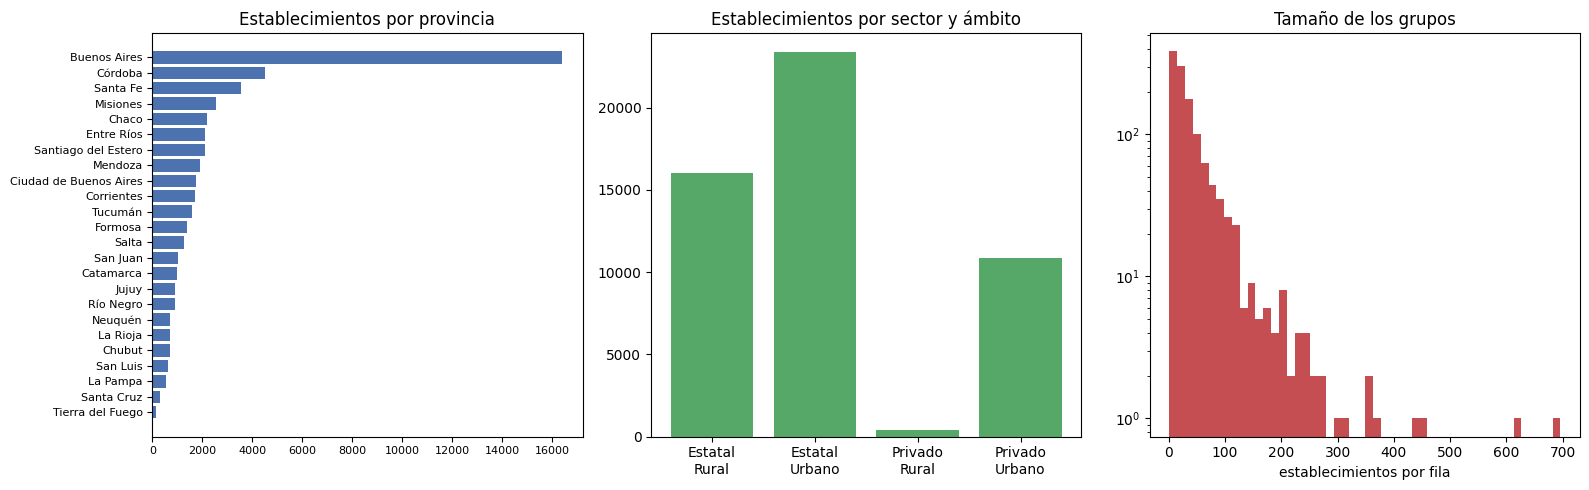

In [8]:
import matplotlib.pyplot as plt

base_eda = df_caracteristicas[IDS].apply(lambda s: s.str.strip()).copy()
base_eda["establecimientos"] = L.values

print("FILAS por sector y ámbito")
print(pd.crosstab(base_eda.sector, base_eda.ambito, margins=True).to_string())
print("\nESTABLECIMIENTOS por sector y ámbito")
print(pd.crosstab(base_eda.sector, base_eda.ambito,
                  values=base_eda.establecimientos, aggfunc="sum", margins=True).round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

pv = base_eda.groupby("provincia").establecimientos.sum().sort_values()
ax[0].barh(pv.index, pv.values, color="#4C72B0")
ax[0].set_title("Establecimientos por provincia")
ax[0].tick_params(labelsize=8)

comp = base_eda.groupby(["sector", "ambito"]).establecimientos.sum()
ax[1].bar([f"{s}\n{a}" for s, a in comp.index], comp.values, color="#55A868")
ax[1].set_title("Establecimientos por sector y ámbito")

ax[2].hist(base_eda.establecimientos, bins=50, color="#C44E52")
ax[2].set_title("Tamaño de los grupos")
ax[2].set_xlabel("establecimientos por fila")
ax[2].set_yscale("log")

plt.tight_layout(); plt.show()


Como hemos dicho anteriormente el dataset de caracteristicas contiene 1216 filas agregadas y representa 50.591 establecimientos. 
La composicion debe analizarse de dos maneras: por cantidad de grupo y por cantidad de establecimientos representados mediante Localizacion. 

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |     454 |     445 |      899 |
| Privado   |      46 |     271 |      317 |
| **Total** | **500** | **716** | **1216** |



La mayoria de filas corresponde al sector estatal, que representa el 73,9% de los grupos. El ámbito urbano concentra 716 filas, frente a 500 rurales.

* *Distribución ponderada por establecimientos*

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |   16003 |   23368 |    39371 |
| Privado   |     388 |   10832 |    11220 |
| **Total** |**16391**|**34200**| **50591**|

Cuando ponderamos por la cantidad de establecimientos representados, el desbalance es todavia mas evidente:

El sector estatal concentra el 77,8% de los establecimientos. 
El sector privado solo representa el 22,2%.
Dentro del ámbito urbano se concentra el 67,6%.
El ámbito rural representa al 32,4%.

La filas ademas tienen tamaños muy diferentes: cada grupo representa entre 1 y 696 establecimientos, con una mediana de 24. Por eso, la cantidad de filas no refleja necesariamente la cantidad de establecimientos representados. 

Este desbalance condiciona la predicción de repitencia. Un modelo podría aprender principalmente los patrones de los grupos estatales y urbano, y tener peor desempeño en grupos privados o rurales. Para controlarlo, deberiamos:

- Incluir sector y ambito como variables explicativas.
- Evaluar el desempeño por subgrupos: estatal/privado y rural/urbano.
- Comparar métricas ponderadas y no ponderadas.
- Conservar matricula_2025 y repitentes_2025 para considerar el tamaño del denominador.
- Evitar que Localizacion domine el modelo como si fuera una medida de infraestructura.
- Revisar especialmente los grupos pequeños, porque sus tasas de repitencia pueden ser muy inestables.

En consecuencia, el objetivo no es obtener segmentos de establecimientos, sino construir una predicción de la tasa de repitencia 2025 para cada grupo provincia × departamento × sector × ámbito, utilizando antecedentes de 2024. El desbalance no invalida el análisis, pero obliga a validar que las predicciones no funcionen únicamente para los grupos mayoritarios.

### Faltantes y su estructura



Características  celdas vacías:  22,371 (29.7% de las celdas de medición)

Columnas de Características con más faltantes:
equipamientobibliotecaequiporeceptorderadioamfm         100.0
equipamientoestablecimientoequiporeceptorderadioamfm    100.0
electricidadgeneradoreólico                              97.6
electricidadgeneradorhidráulico                          97.2
subvenciónestataljardínmaternalsi                        87.7
subvenciónestatalsnusi                                   85.0
electricidadotro                                         79.6
subvenciónestataljardíndeinfantessi                      76.4


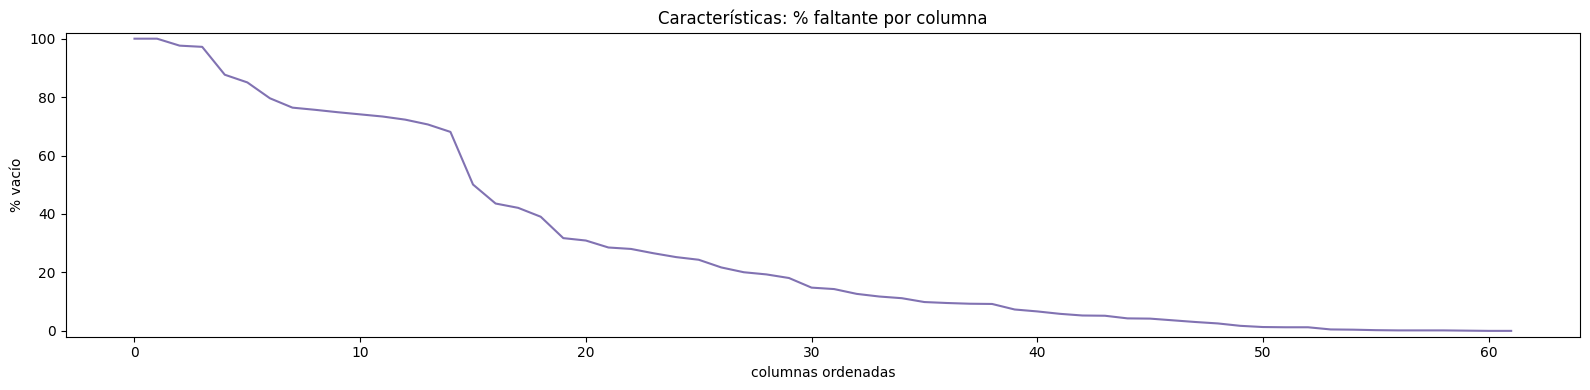

In [9]:
falt = {}

nombre = "Características"
d = df_caracteristicas

cols = [c for c in d.columns if c not in IDS]

S_ = d[cols].apply(
    lambda s: s.str.strip().replace("", np.nan)
)

falt[nombre] = S_.isna().mean() * 100

print(
    f"{nombre:<16} "
    f"celdas vacías: {S_.isna().sum().sum():>7,} "
    f"({S_.isna().mean().mean() * 100:>4.1f}% "
    f"de las celdas de medición)"
)

print("\nColumnas de Características con más faltantes:")
print(
    falt[nombre]
    .sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(16, 4))

serie = falt[nombre]

ax.plot(
    range(len(serie)),
    sorted(serie.values, reverse=True),
    color="#8172B2"
)

ax.set_title(f"{nombre}: % faltante por columna")
ax.set_xlabel("columnas ordenadas")
ax.set_ylabel("% vacío")
ax.set_ylim(-2, 102)

plt.tight_layout()
plt.show()



> **`[ A REDACTAR ]`**  Qué muestra el patrón de faltantes
>
> Tu lectura tiene que responder: *¿cuántos faltantes hay?*, *¿están repartidos al azar o
> concentrados?* y *¿qué decisión de limpieza anticipa eso?* (esa decisión se desarrolla en 5.1)
>
> Material que imprime la celda:
>
> - el porcentaje de celdas vacías de cada base
> - las columnas con más faltantes
> - el gráfico de faltantes por columna, que muestra si el patrón es parejo o por bloques


>La base de Características presenta 22.371 celdas vacías, equivalentes al 29,7% de las celdas de medición. Los faltantes no están distribuidos de manera >uniforme, sino concentrados en bloques específicos.
>Las columnas con mayor ausencia corresponden a equipamiento poco frecuente, fuentes alternativas de energía y subvenciones para niveles que no están >presentes en todos los grupos. Algunas variables, como los receptores de radio en establecimientos y bibliotecas, tienen 100% de valores vacíos.
>Esto anticipa que no debe aplicarse una imputación global. Las columnas completamente vacías deberían excluirse, mientras que las variables con faltantes >asociados a la aplicabilidad del servicio deberán analizarse antes de decidir si se convierten en cero, se mantienen como faltantes o se acompañan con >una variable indicadora.

### Infraestructura: cómo se distribuye

COBERTURA MEDIA (% de establecimientos del grupo)

                electricidad  internet_aulas  laboratorio  biblioteca
sector  ambito                                                       
Estatal Rural           98.0            54.1         22.9        61.7
        Urbano          99.4            58.5         37.0        76.5
Privado Rural           99.3            45.0         33.1        61.5
        Urbano          98.9            67.3         50.0        67.8


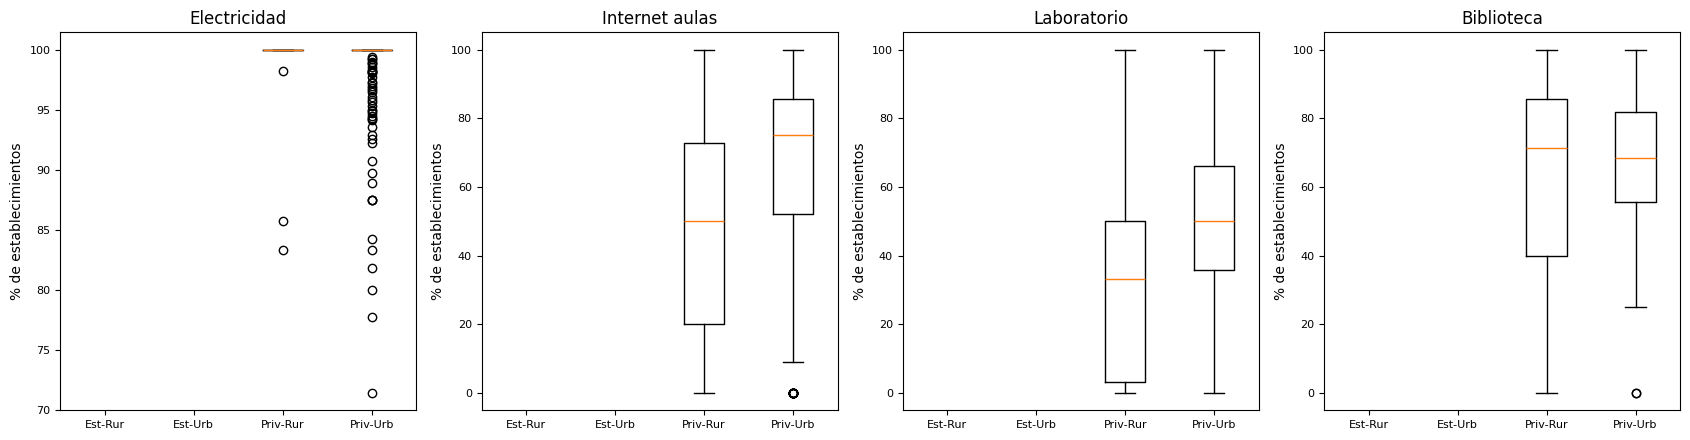

In [10]:
num_eda = lambda c: pd.to_numeric(df_caracteristicas[c].astype("string").str.strip().replace("", np.nan), errors="coerce").fillna(0)

ind = base_eda.copy()
ind["electricidad"]   = num_eda("electricidadsi") / L * 100
ind["internet_aulas"] = num_eda("espaciosconconexiónenlasaulas") / L * 100
ind["laboratorio"]    = num_eda("disponedesalaolaboratoriodeinformáticasi") / L * 100
ind["biblioteca"]     = num_eda("bibliotecadisponedealmenosunasi") / L * 100
VARS = ["electricidad", "internet_aulas", "laboratorio", "biblioteca"]

print("COBERTURA MEDIA (% de establecimientos del grupo)\n")
print(ind.groupby(["sector", "ambito"])[VARS].mean().round(1).to_string())

fig, ax = plt.subplots(1, 4, figsize=(17, 4.5))
for i, v in enumerate(VARS):
    datos = [ind[(ind.sector == s) & (ind.ambito == a)][v].dropna()
             for s in ["Eestatal", "Privado"] for a in ["Rural", "Urbano"]]
    ax[i].boxplot(datos)
    ax[i].set_xticks(range(1, 5))
    ax[i].set_xticklabels(["Est-Rur", "Est-Urb", "Priv-Rur", "Priv-Urb"])
    ax[i].set_title(v.replace("_", " ").capitalize()); ax[i].set_ylabel("% de establecimientos")
    ax[i].tick_params(labelsize=8)
plt.tight_layout(); plt.show()


> **`[ A REDACTAR ]`**  Qué muestran las brechas de infraestructura
>
> Tu lectura tiene que responder: *¿qué tan desigual es el acceso?*, *¿entre qué grupos está
> la brecha más grande?* y *¿alcanza esa heterogeneidad para que tenga sentido segmentar?*
> (esto último es lo que justifica el proyecto)
>
> Material que imprime la celda:
>
> - cobertura de electricidad, internet en aulas y laboratorio, por sector y ámbito
> - los boxplots que muestran la dispersión dentro de cada grupo

>La cobertura eléctrica es elevada y homogénea en los cuatro grupos analizados, con valores entre 98,0% y 99,4%. Por lo tanto, aunque representa una ?>condición básica importante, presenta poca variabilidad y probablemente tenga una capacidad limitada para diferenciar los grupos en la predicción.
>Las mayores brechas aparecen en la conectividad y en la disponibilidad de laboratorios. La cobertura de internet en aulas varía entre 45,0% en el sector >privado rural y 67,3% en el privado urbano, una diferencia de 22,3 puntos porcentuales. En los laboratorios, la cobertura va desde 22,9% en el sector .estatal rural hasta 50,0% en el privado urbano, con una brecha de 27,1 puntos porcentuales.
>La disponibilidad de bibliotecas presenta diferencias menores, aunque también relevantes: alcanza 76,5% en el sector estatal urbano y 61,5% en el privado >rural. Los boxplots permiten complementar estas medias y observar la dispersión interna de cada grupo.
>En consecuencia, las condiciones de infraestructura no son homogéneas. La variabilidad observada, especialmente en internet en aulas y laboratorios, >justifica incorporar estas variables como posibles predictores de la repitencia 2025. No debe interpretarse esta heterogeneidad como evidencia causal, >sino como una diferencia observable entre los grupos agregados.

---
## Dataset Matricula

### Composicion de la muestra

FILAS por sector y ámbito
ambito   Rural  Urbano   All
sector                      
Estatal    454     445   899
Privado     46     271   317
All        500     716  1216

ESTABLECIMIENTOS por sector y ámbito
ambito   Rural  Urbano    All
sector                       
Estatal  15922   23259  39181
Privado    387   10759  11146
All      16309   34018  50327


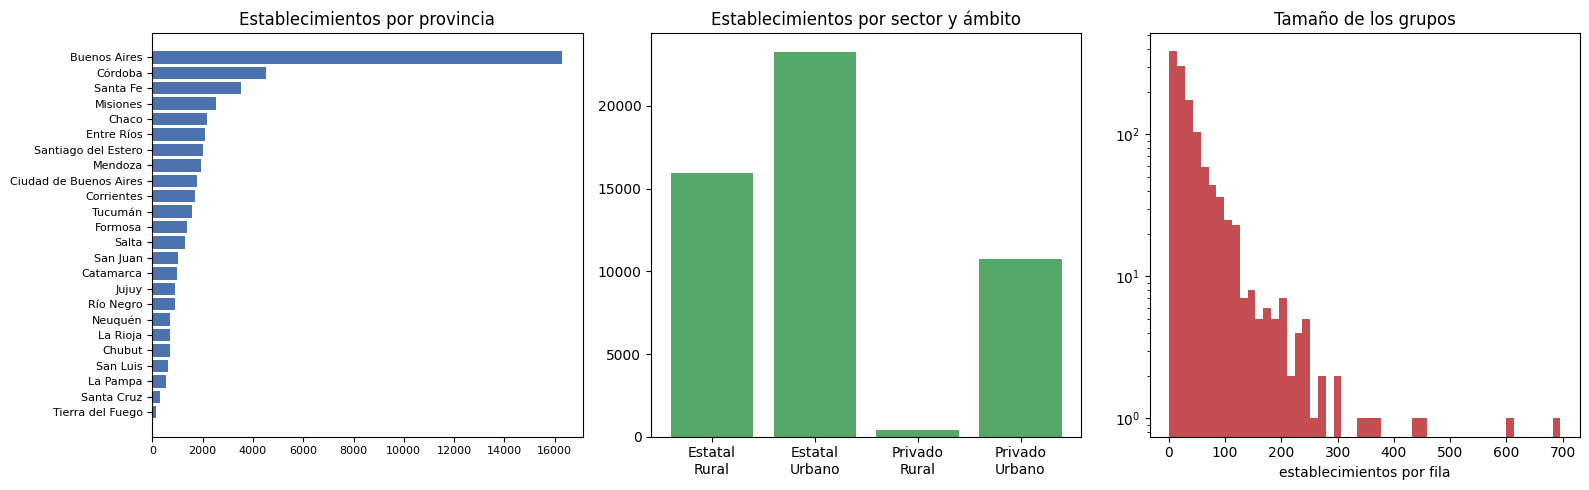

In [11]:
base_eda_matriculas = df_matriculas[IDS + ["localizacion"]].copy()
base_eda_matriculas[IDS] = base_eda_matriculas[IDS].apply(
    lambda s: s.astype("string").str.strip()
)

base_eda_matriculas["establecimientos"] = pd.to_numeric(
    base_eda_matriculas["localizacion"],
    errors="coerce"
)

base_eda_matriculas = base_eda_matriculas.drop(columns=["localizacion"])

print("FILAS por sector y ámbito")
print(pd.crosstab(base_eda_matriculas.sector, base_eda_matriculas.ambito, margins=True).to_string())
print("\nESTABLECIMIENTOS por sector y ámbito")
print(pd.crosstab(base_eda_matriculas.sector, base_eda_matriculas.ambito,
                  values=base_eda_matriculas.establecimientos, aggfunc="sum", margins=True).round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

pv = base_eda_matriculas.groupby("provincia").establecimientos.sum().sort_values()
ax[0].barh(pv.index, pv.values, color="#4C72B0")
ax[0].set_title("Establecimientos por provincia")
ax[0].tick_params(labelsize=8)

comp = base_eda_matriculas.groupby(["sector", "ambito"]).establecimientos.sum()
ax[1].bar([f"{s}\n{a}" for s, a in comp.index], comp.values, color="#55A868")
ax[1].set_title("Establecimientos por sector y ámbito")

ax[2].hist(base_eda_matriculas.establecimientos, bins=50, color="#C44E52")
ax[2].set_title("Tamaño de los grupos")
ax[2].set_xlabel("establecimientos por fila")
ax[2].set_yscale("log")

plt.tight_layout(); plt.show()

Como hemos dicho anteriormente el dataset de caracteristicas contiene 1216 filas agregadas y representa 50.327 establecimientos. Aca encontramos la primera diferencia que debemos corroborar con los datos de Caracteristicas, si bien los registros agregados por provincia x ambito x setor x localizacion coinciden (filas), no asi los establecimientos.
La composicion debe analizarse de dos maneras: por cantidad de grupo y por cantidad de establecimientos representados mediante Localizacion. 

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |     454 |     445 |      899 |
| Privado   |      46 |     271 |      317 |
| **Total** | **500** | **716** | **1216** |



* *Distribución ponderada por establecimientos*

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |   15922 |   23259 |    39181 |
| Privado   |     387 |   10759 |    11146 |
| **Total** |**16309**|**34018**| **50327**|

### Faltantes

Matriculas       celdas vacías:  22,264 (18.3% de las celdas de medición)

Columnas de Matriculas con más faltantes:
s_deambulantes    97.3
s_lactantes       97.2
s_s2              96.6
s_s3              91.2
_20               90.0
v_20              90.0
r_20              90.0
s_s4              84.5


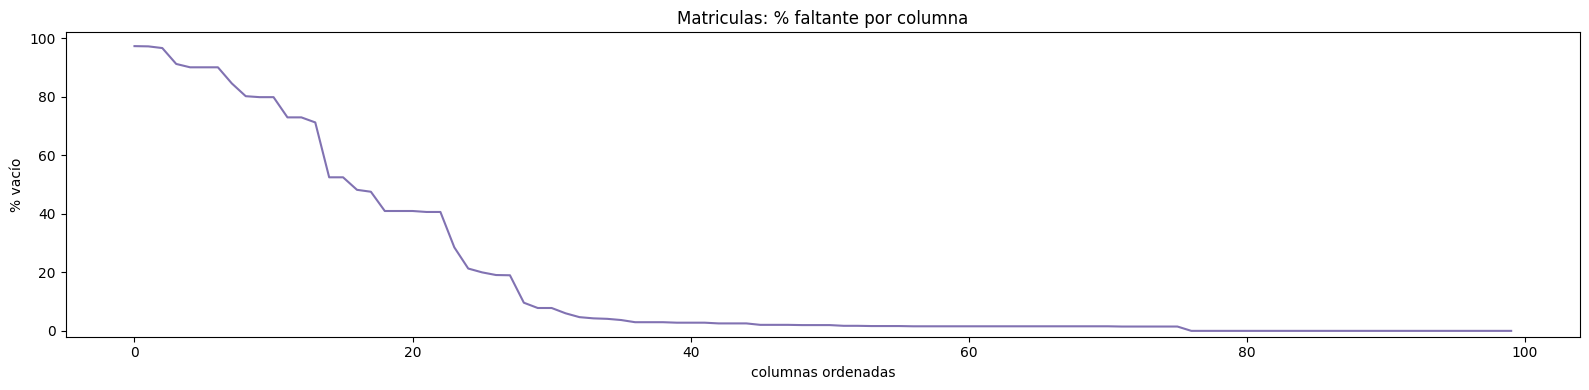

In [12]:
falt = {}

nombre = "Matriculas"
d = df_matriculas

cols = [c for c in d.columns if c not in IDS]

S_ = d[cols].apply(
    lambda s: s.str.strip().replace("", np.nan)
)

falt[nombre] = S_.isna().mean() * 100

print(
    f"{nombre:<16} "
    f"celdas vacías: {S_.isna().sum().sum():>7,} "
    f"({S_.isna().mean().mean() * 100:>4.1f}% "
    f"de las celdas de medición)"
)

print("\nColumnas de Matriculas con más faltantes:")
print(
    falt[nombre]
    .sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(16, 4))

serie = falt[nombre]

ax.plot(
    range(len(serie)),
    sorted(serie.values, reverse=True),
    color="#8172B2"
)

ax.set_title(f"{nombre}: % faltante por columna")
ax.set_xlabel("columnas ordenadas")
ax.set_ylabel("% vacío")
ax.set_ylim(-2, 102)

plt.tight_layout()
plt.show()

> **`[ A REDACTAR ]`**  Qué muestra el patrón de faltantes
>
> Tu lectura tiene que responder: *¿cuántos faltantes hay?*, *¿están repartidos al azar o
> concentrados?* y *¿qué decisión de limpieza anticipa eso?* (esa decisión se desarrolla en 5.1)
>
> Material que imprime la celda:
>
> - el porcentaje de celdas vacías de cada base
> - las columnas con más faltantes
> - el gráfico de faltantes por columna, que muestra si el patrón es parejo o por bloques


>La base de Matrícula contiene 22.264 celdas vacías, equivalentes al 18,3% de las celdas de medición. El patrón tampoco es aleatorio: los faltantes se >concentran principalmente en salas del nivel inicial y en las categorías _20.
>Las variables s_deambulantes, s_lactantes, s_s2 y s_s3 superan el 90% de valores vacíos, mientras que _20, v_20 y r_20 alcanzan el 90%. Esto sugiere que >muchos campos no aplican a todos los grupos educativos, en lugar de representar necesariamente datos perdidos.
>La limpieza deberá diferenciar entre variables no aplicables y datos realmente ausentes. No conviene reemplazar todos los blancos por cero sin verificar >previamente la definición de cada bloque educativo.


### Infraestructura: cómo se distribuye

TASAS MEDIAS POR SECTOR Y ÁMBITO

                tasa_repitencia  tasa_sobreedad
sector  ambito                                 
Estatal Rural               5.0            14.3
        Urbano              5.6            15.0
Privado Rural               4.4            15.3
        Urbano              1.3             4.1

TASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS

                matricula_total  repitentes_total  sobreedad_total  tasa_repitencia  tasa_sobreedad
sector  ambito                                                                                     
Estatal Rural          700069.0           38149.0         111891.0              5.4            16.0
        Urbano        5590000.0          319619.0         887541.0              5.7            15.9
Privado Rural           37937.0            1430.0           4858.0              3.8            12.8
        Urbano        2379490.0           25845.0          87848.0              1.1             3.7


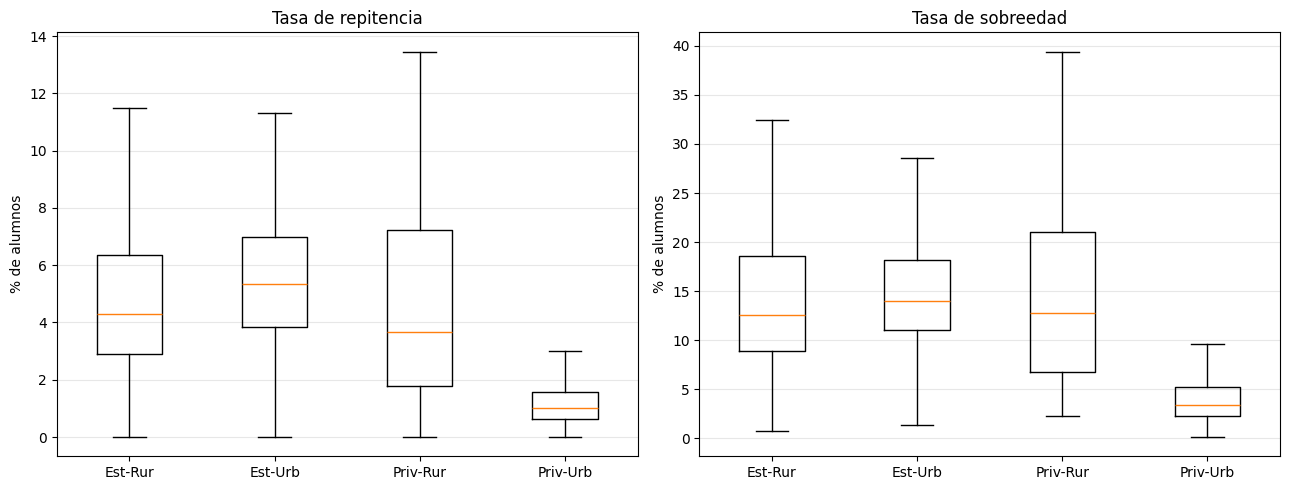

In [13]:
grados = range(1, 13)

def sumar_grados(df, prefijo):
    columnas = [
        f"{prefijo}_{grado}"
        for grado in grados
        if f"{prefijo}_{grado}" in df.columns
    ]

    return (
        df[columnas]
        .apply(pd.to_numeric, errors="coerce")
        .sum(axis=1, min_count=1)
    )


base_eda_matriculas = df_matriculas.copy()

base_eda_matriculas[IDS] = base_eda_matriculas[IDS].apply(
    lambda s: s.astype("string").str.strip()
)

base_eda_matriculas["establecimientos"] = pd.to_numeric(
    base_eda_matriculas["localizacion"],
    errors="coerce"
)

base_eda_matriculas["matricula_total"] = sumar_grados(
    base_eda_matriculas,
    ""
)

base_eda_matriculas["repitentes_total"] = sumar_grados(
    base_eda_matriculas,
    "r"
)

base_eda_matriculas["sobreedad_total"] = sumar_grados(
    base_eda_matriculas,
    "s"
)

base_eda_matriculas["tasa_repitencia"] = (
    base_eda_matriculas["repitentes_total"]
    / base_eda_matriculas["matricula_total"].replace(0, np.nan)
    * 100
)

base_eda_matriculas["tasa_sobreedad"] = (
    base_eda_matriculas["sobreedad_total"]
    / base_eda_matriculas["matricula_total"].replace(0, np.nan)
    * 100
)

VARS_MATRICULA = [
    "tasa_repitencia",
    "tasa_sobreedad"
]

print("TASAS MEDIAS POR SECTOR Y ÁMBITO\n")
print(
    base_eda_matriculas
    .groupby(["sector", "ambito"])[VARS_MATRICULA]
    .mean()
    .round(1)
    .to_string()
)

print("\nTASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS\n")

totales_matricula = (
    base_eda_matriculas
    .groupby(["sector", "ambito"])[
        [
            "matricula_total",
            "repitentes_total",
            "sobreedad_total"
        ]
    ]
    .sum()
)

totales_matricula["tasa_repitencia"] = (
    totales_matricula["repitentes_total"]
    / totales_matricula["matricula_total"]
    * 100
)

totales_matricula["tasa_sobreedad"] = (
    totales_matricula["sobreedad_total"]
    / totales_matricula["matricula_total"]
    * 100
)

print(
    totales_matricula[
        [
            "matricula_total",
            "repitentes_total",
            "sobreedad_total",
            "tasa_repitencia",
            "tasa_sobreedad"
        ]
    ]
    .round(1)
    .to_string()
)

combinaciones = [
    ("Estatal", "Rural"),
    ("Estatal", "Urbano"),
    ("Privado", "Rural"),
    ("Privado", "Urbano")
]

etiquetas = [
    "Est-Rur",
    "Est-Urb",
    "Priv-Rur",
    "Priv-Urb"
]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for eje, variable, titulo in zip(
    ax,
    ["tasa_repitencia", "tasa_sobreedad"],
    ["Tasa de repitencia", "Tasa de sobreedad"]
):
    datos = [
        base_eda_matriculas.loc[
            (base_eda_matriculas["sector"] == sector)
            & (base_eda_matriculas["ambito"] == ambito),
            variable
        ].dropna()
        for sector, ambito in combinaciones
    ]

    eje.boxplot(datos, labels=etiquetas, showfliers=False)
    eje.set_title(titulo)
    eje.set_ylabel("% de alumnos")
    eje.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

> **`[ A REDACTAR ]`**  Qué muestran las brechas de infraestructura
>
> Tu lectura tiene que responder: *¿qué tan desigual es el acceso?*, *¿entre qué grupos está
> la brecha más grande?* y *¿alcanza esa heterogeneidad para que tenga sentido segmentar?*
> (esto último es lo que justifica el proyecto)
>
> Material que imprime la celda:
>
> - cobertura de electricidad, internet en aulas y laboratorio, por sector y ámbito
> - los boxplots que muestran la dispersión dentro de cada grupo

>La base de Matrícula 2024 muestra diferencias en las tasas de repitencia y sobreedad según sector y ámbito. La tasa media de repitencia varía entre 1,3% >en el sector privado urbano y 5,6% en el estatal urbano, lo que representa una diferencia de 4,3 puntos porcentuales.
>Cuando se calculan las tasas agregadas utilizando el total de alumnos como denominador, la repitencia alcanza 5,7% en el sector estatal urbano y 1,1% en >el privado urbano. Esto confirma una diferencia importante entre ambos grupos, aunque las tasas agregadas representan al conjunto de alumnos y no el >comportamiento promedio de cada grupo territorial.
>La sobreedad presenta brechas aún mayores. La tasa media varía entre 4,1% en el sector privado urbano y 15,3% en el privado rural. En las tasas >agregadas, los valores oscilan entre 3,7% en el privado urbano y 16,0% en el estatal rural.
>Estas diferencias indican que Matrícula 2024 aporta antecedentes relevantes para la predicción de la repitencia 2025. En particular, resultan >potencialmente útiles la repitencia previa, la sobreedad, el tamaño de la matrícula, el sector y el ámbito.
>La diferencia entre las medias simples y las tasas agregadas también muestra que los grupos tienen tamaños muy diferentes. Por eso, para el modelo >conviene conservar los conteos de matrícula y repitentes, además de las tasas, y evitar interpretar únicamente el promedio simple de las tasas por grupo.

---
## Dataset Trayectoria


### Composicion de la muestra

Correspondencia con Características:
_merge
both          1207
left_only        2
right_only       0
Name: count, dtype: int64

Claves de Trayectoria sin correspondencia:
provincia departamento  sector ambito
  Formosa    Sin datos Estatal  Rural
  Tucumán    Sin datos Estatal  Rural
FILAS por sector y ámbito
ambito   Rural  Urbano   All
sector                      
Estatal    456     445   901
Privado     39     269   308
All        495     714  1209

ESTABLECIMIENTOS por sector y ámbito
ambito     Rural   Urbano      All
sector                            
Estatal  16003.0  23368.0  39371.0
Privado    341.0  10820.0  11161.0
All      16344.0  34188.0  50532.0


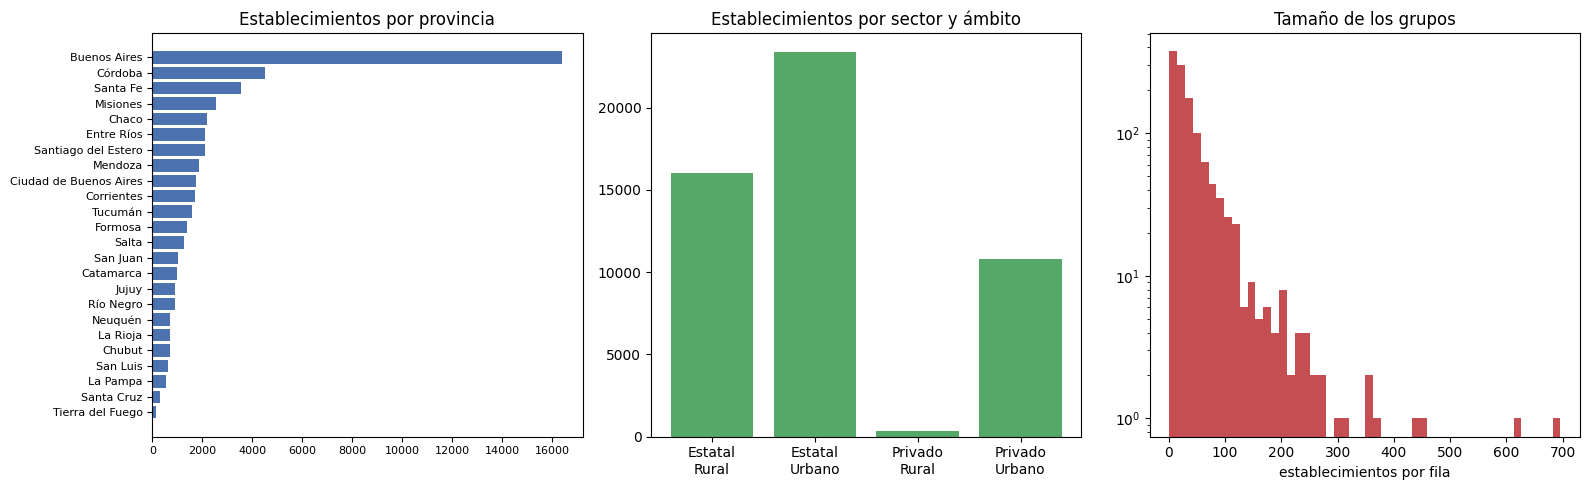

In [14]:
base_eda_trayectoria = (
    df_trayectoria[IDS]
    .copy()
    .merge(
        df_caracteristicas[IDS + ["localizacion"]],
        on=IDS,
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

base_eda_trayectoria["establecimientos"] = pd.to_numeric(
    base_eda_trayectoria["localizacion"],
    errors="coerce"
)

print("Correspondencia con Características:")
print(base_eda_trayectoria["_merge"].value_counts())

faltantes = base_eda_trayectoria[
    base_eda_trayectoria["_merge"] != "both"
]

if not faltantes.empty:
    print("\nClaves de Trayectoria sin correspondencia:")
    print(faltantes[IDS].to_string(index=False))

base_eda_trayectoria = base_eda_trayectoria.drop(
    columns=["localizacion", "_merge"]
)

print("FILAS por sector y ámbito")
print(
    pd.crosstab(
        base_eda_trayectoria["sector"],
        base_eda_trayectoria["ambito"],
        margins=True
    ).to_string()
)

print("\nESTABLECIMIENTOS por sector y ámbito")
print(
    pd.crosstab(
        base_eda_trayectoria["sector"],
        base_eda_trayectoria["ambito"],
        values=base_eda_trayectoria["establecimientos"],
        aggfunc="sum",
        margins=True
    ).round(0).to_string()
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

pv = (
    base_eda_trayectoria
    .groupby("provincia")["establecimientos"]
    .sum()
    .sort_values()
)

ax[0].barh(pv.index, pv.values, color="#4C72B0")
ax[0].set_title("Establecimientos por provincia")
ax[0].tick_params(labelsize=8)

comp = (
    base_eda_trayectoria
    .groupby(["sector", "ambito"])["establecimientos"]
    .sum()
)

ax[1].bar(
    [f"{s}\n{a}" for s, a in comp.index],
    comp.values,
    color="#55A868"
)
ax[1].set_title("Establecimientos por sector y ámbito")

ax[2].hist(
    base_eda_trayectoria["establecimientos"].dropna(),
    bins=50,
    color="#C44E52"
)
ax[2].set_title("Tamaño de los grupos")
ax[2].set_xlabel("establecimientos por fila")
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()

### Faltantes

Trayectoria      celdas vacías:  37,496 (10.9% de las celdas de medición)

Columnas de Trayectoria con más faltantes:
m_otros_20            99.8
m_nopromo_20          99.8
otros_20              99.8
promovidos_ex_20      99.8
nopromo_20            99.8
m_promovidos_ex_20    99.8
regulares_20          99.8
m_regulares_20        99.8


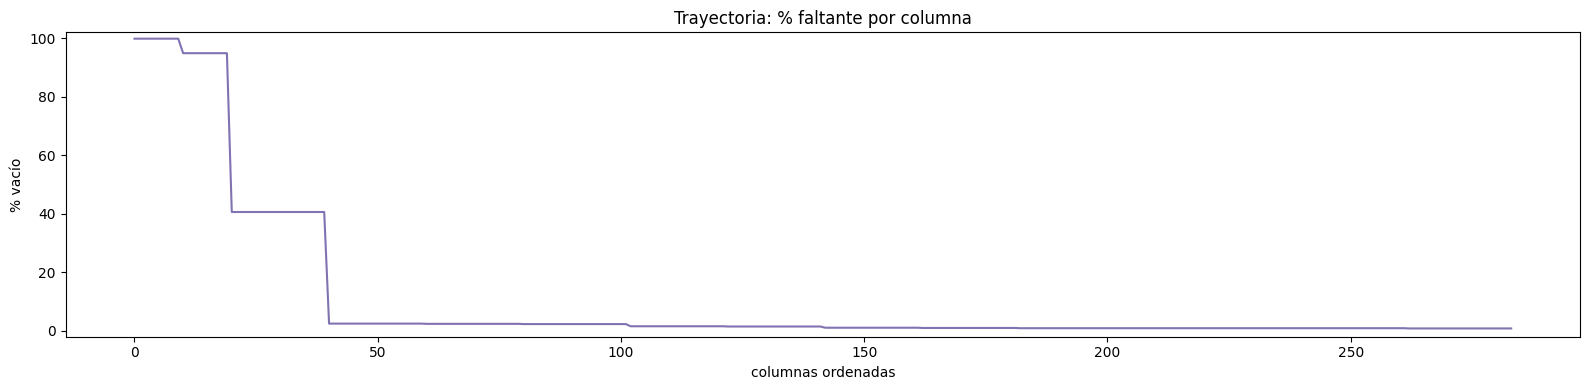

In [15]:
nombre = "Trayectoria"
d = df_trayectoria

cols = [c for c in d.columns if c not in IDS]

S_ = d[cols].apply(
    lambda s: s.str.strip().replace("", np.nan)
)

falt[nombre] = S_.isna().mean() * 100

print(
    f"{nombre:<16} "
    f"celdas vacías: {S_.isna().sum().sum():>7,} "
    f"({S_.isna().mean().mean() * 100:>4.1f}% "
    f"de las celdas de medición)"
)

print("\nColumnas de Trayectoria con más faltantes:")
print(
    falt[nombre]
    .sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(16, 4))

serie = falt[nombre]

ax.plot(
    range(len(serie)),
    sorted(serie.values, reverse=True),
    color="#8172B2"
)

ax.set_title(f"{nombre}: % faltante por columna")
ax.set_xlabel("columnas ordenadas")
ax.set_ylabel("% vacío")
ax.set_ylim(-2, 102)

plt.tight_layout()
plt.show()

> **`[ A REDACTAR ]`**  Qué muestra el patrón de faltantes
>
> Tu lectura tiene que responder: *¿cuántos faltantes hay?*, *¿están repartidos al azar o
> concentrados?* y *¿qué decisión de limpieza anticipa eso?* (esa decisión se desarrolla en 5.1)
>
> Material que imprime la celda:
>
> - el porcentaje de celdas vacías de cada base
> - las columnas con más faltantes
> - el gráfico de faltantes por columna, que muestra si el patrón es parejo o por bloques

>Trayectoria presenta 37.496 celdas vacías, equivalentes al 10,9% de las celdas de medición. Los faltantes se concentran casi exclusivamente en las >categorías _20, especialmente en otros, regulares, nopromo y promovidos_ex, junto con sus variantes por sexo.
>Este patrón indica que los faltantes están asociados a categorías o niveles que no corresponden a la mayoría de los grupos, y no que se distribuyan >aleatoriamente. Por eso, no sería correcto imputarlos automáticamente con la media o con cero.
>En conjunto, las tres bases muestran faltantes estructurales por bloques. La decisión de limpieza deberá comenzar clasificando cada columna como >aplicable, no aplicable, cero real o dato desconocido. Las columnas completamente vacías o sin variabilidad deberían excluirse, mientras que las >restantes deberán conservarse o imputarse únicamente después de confirmar su significado metodológico.

### Infraestructura: cómo se distribuye

Correspondencia con Características:
_merge
both          1207
left_only        2
right_only       0

TASAS MEDIAS POR SECTOR Y ÁMBITO

                tasa_salidos_sin_pase  tasa_salidos_con_pase  tasa_retencion  tasa_promocion  tasa_no_promocion
sector  ambito                                                                                                 
Estatal Rural                     1.0                    3.8            95.2            84.7                6.2
        Urbano                    0.9                    3.2            95.9            78.6                8.6
Privado Rural                     1.7                    3.1            95.2            73.0                8.5
        Urbano                    0.2                    1.3            98.4            84.2                3.3

TASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS

                tasa_salidos_sin_pase  tasa_salidos_con_pase  tasa_retencion  tasa_promocion  tasa_no_promocion
sector  ambito                      

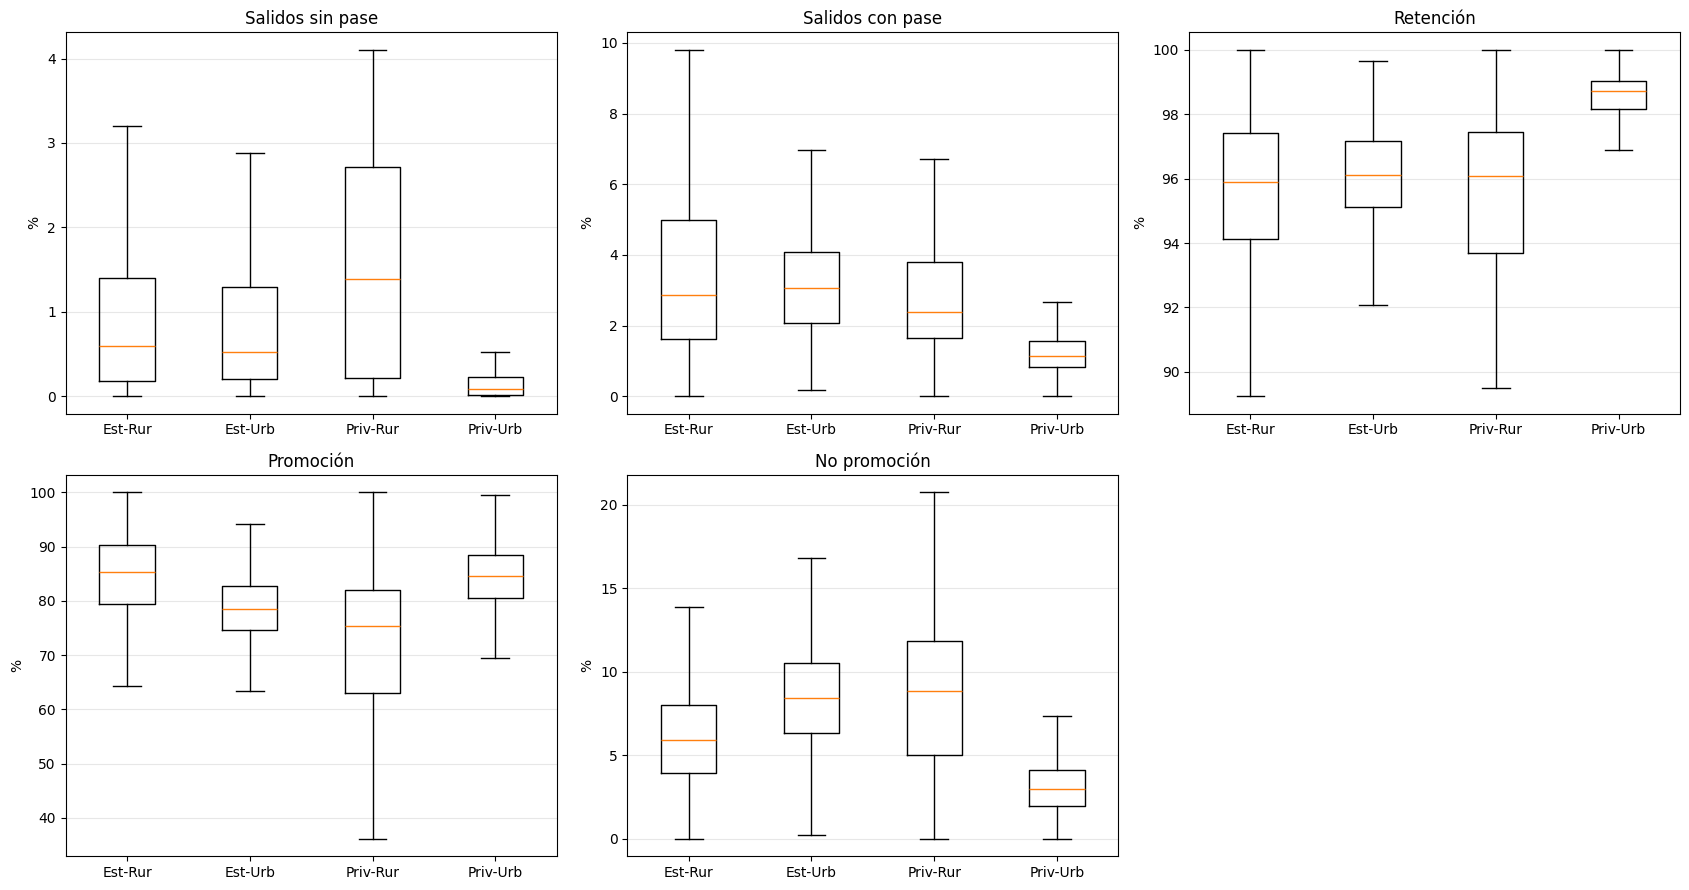

In [16]:
grados = range(1, 13)

def sumar_trayectoria(df, prefijo):
    columnas = [
        f"{prefijo}_{grado}"
        for grado in grados
        if f"{prefijo}_{grado}" in df.columns
    ]

    return (
        df[columnas]
        .apply(pd.to_numeric, errors="coerce")
        .sum(axis=1, min_count=1)
    )


base_eda_trayectoria = (
    df_trayectoria
    .copy()
    .merge(
        df_caracteristicas[IDS + ["localizacion"]],
        on=IDS,
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

print("Correspondencia con Características:")
print(
    base_eda_trayectoria["_merge"]
    .value_counts()
    .to_string()
)

base_eda_trayectoria["establecimientos"] = pd.to_numeric(
    base_eda_trayectoria["localizacion"],
    errors="coerce"
)

categorias = [
    "inicial",
    "entrados",
    "ssp",
    "scp",
    "ultimo",
    "promovidos",
    "promovidos_ex",
    "nopromo"
]

for categoria in categorias:
    base_eda_trayectoria[categoria] = sumar_trayectoria(
        base_eda_trayectoria,
        categoria
    )

base_eda_trayectoria["matricula_disponible"] = (
    base_eda_trayectoria["inicial"]
    + base_eda_trayectoria["entrados"]
)

base_eda_trayectoria["tasa_entrados"] = (
    base_eda_trayectoria["entrados"]
    / base_eda_trayectoria["inicial"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_salidos_sin_pase"] = (
    base_eda_trayectoria["ssp"]
    / base_eda_trayectoria["matricula_disponible"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_salidos_con_pase"] = (
    base_eda_trayectoria["scp"]
    / base_eda_trayectoria["matricula_disponible"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_retencion"] = (
    base_eda_trayectoria["ultimo"]
    / base_eda_trayectoria["matricula_disponible"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_promocion"] = (
    base_eda_trayectoria["promovidos"]
    / base_eda_trayectoria["ultimo"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_promocion_examen"] = (
    base_eda_trayectoria["promovidos_ex"]
    / base_eda_trayectoria["ultimo"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_no_promocion"] = (
    base_eda_trayectoria["nopromo"]
    / base_eda_trayectoria["ultimo"].replace(0, np.nan)
    * 100
)

VARS_TRAYECTORIA = [
    "tasa_salidos_sin_pase",
    "tasa_salidos_con_pase",
    "tasa_retencion",
    "tasa_promocion",
    "tasa_no_promocion"
]

print("\nTASAS MEDIAS POR SECTOR Y ÁMBITO\n")
print(
    base_eda_trayectoria
    .groupby(["sector", "ambito"])[VARS_TRAYECTORIA]
    .mean()
    .round(1)
    .to_string()
)

print("\nTASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS\n")

totales_trayectoria = (
    base_eda_trayectoria
    .groupby(["sector", "ambito"])[
        [
            "inicial",
            "entrados",
            "ssp",
            "scp",
            "ultimo",
            "promovidos",
            "promovidos_ex",
            "nopromo"
        ]
    ]
    .sum()
)

totales_trayectoria["matricula_disponible"] = (
    totales_trayectoria["inicial"]
    + totales_trayectoria["entrados"]
)

totales_trayectoria["tasa_salidos_sin_pase"] = (
    totales_trayectoria["ssp"]
    / totales_trayectoria["matricula_disponible"]
    * 100
)

totales_trayectoria["tasa_salidos_con_pase"] = (
    totales_trayectoria["scp"]
    / totales_trayectoria["matricula_disponible"]
    * 100
)

totales_trayectoria["tasa_retencion"] = (
    totales_trayectoria["ultimo"]
    / totales_trayectoria["matricula_disponible"]
    * 100
)

totales_trayectoria["tasa_promocion"] = (
    totales_trayectoria["promovidos"]
    / totales_trayectoria["ultimo"]
    * 100
)

totales_trayectoria["tasa_no_promocion"] = (
    totales_trayectoria["nopromo"]
    / totales_trayectoria["ultimo"]
    * 100
)

print(
    totales_trayectoria[VARS_TRAYECTORIA]
    .round(1)
    .to_string()
)

combinaciones = [
    ("Estatal", "Rural"),
    ("Estatal", "Urbano"),
    ("Privado", "Rural"),
    ("Privado", "Urbano")
]

etiquetas = [
    "Est-Rur",
    "Est-Urb",
    "Priv-Rur",
    "Priv-Urb"
]

fig, ax = plt.subplots(2, 3, figsize=(17, 9))

variables_grafico = [
    ("tasa_salidos_sin_pase", "Salidos sin pase"),
    ("tasa_salidos_con_pase", "Salidos con pase"),
    ("tasa_retencion", "Retención"),
    ("tasa_promocion", "Promoción"),
    ("tasa_no_promocion", "No promoción")
]

for eje, (variable, titulo) in zip(ax.ravel(), variables_grafico):
    datos = [
        base_eda_trayectoria.loc[
            (base_eda_trayectoria["sector"] == sector)
            & (base_eda_trayectoria["ambito"] == ambito),
            variable
        ].dropna()
        for sector, ambito in combinaciones
    ]

    eje.boxplot(datos, labels=etiquetas, showfliers=False)
    eje.set_title(titulo)
    eje.set_ylabel("%")
    eje.grid(axis="y", alpha=0.3)

ax.ravel()[-1].axis("off")

plt.tight_layout()
plt.show()

> **`[ A REDACTAR ]`**  Qué muestran las brechas de infraestructura
>
> Tu lectura tiene que responder: *¿qué tan desigual es el acceso?*, *¿entre qué grupos está
> la brecha más grande?* y *¿alcanza esa heterogeneidad para que tenga sentido segmentar?*
> (esto último es lo que justifica el proyecto)
>
> Material que imprime la celda:
>
> - cobertura de electricidad, internet en aulas y laboratorio, por sector y ámbito
> - los boxplots que muestran la dispersión dentro de cada grupo

>La base de Trayectoria 2024 presenta diferencias entre los grupos en los indicadores de movilidad, retención y desempeño educativo. La tasa media de >salidos sin pase varía entre 0,2% en el sector privado urbano y 1,7% en el privado rural. Esta variable debe interpretarse como salidos sin pase y no >como abandono automático.
>Los salidos con pase alcanzan sus valores medios más altos en el sector estatal rural, con 3,8%, y en el estatal urbano, con 3,2%. En el sector privado >urbano la tasa es de 1,3%. Este indicador representa movilidad hacia otro establecimiento, por lo que no debe interpretarse necesariamente como un >resultado negativo.
>La retención final es elevada en todos los grupos. El sector privado urbano presenta el valor más alto, con 98,4% en la media por grupo y 98,6% en la >tasa agregada. Los demás grupos se ubican aproximadamente entre 95% y 96%.
>Las mayores diferencias aparecen en las tasas de promoción y no promoción. La promoción media varía entre 73,0% en el sector privado rural y 84,7% en el >estatal rural. En las tasas agregadas, los valores se ubican entre 74,9% en el privado rural y 84,3% en el privado urbano.
>La tasa de no promoción alcanza su valor más alto en el sector estatal urbano, con 8,6% en la media por grupo y 9,0% en la tasa agregada. En el sector >privado urbano, en cambio, se ubica en 3,3% y 3,0%, respectivamente.
>Estas diferencias muestran que Trayectoria 2024 puede aportar antecedentes relevantes para la predicción de repitencia 2025 mediante variables como >salidos sin pase, retención, promoción y no promoción. Sin embargo, nopromo no equivale directamente a repitencia y ssp no equivale automáticamente a >abandono. Son indicadores de trayectoria educativa que deben incorporarse como predictores diferenciados.

--- 


---
## 4.5 Los indicadores de trayectoria


TASAS POR GRUPO AGREGADO (%)

          count   mean    50%    max
rep_pri  1198.0   1.99   0.89  21.43
rep_sec  1200.0   6.95   6.39  48.21
sob_pri  1198.0   5.11   2.91  51.09
sob_sec  1200.0  20.44  20.32  75.45

POR SECTOR Y ÁMBITO

                rep_pri  rep_sec  sob_pri  sob_sec
sector  ambito                                    
Estatal Rural      2.71     7.93     6.82    24.31
        Urbano     2.29     9.03     5.60    24.99
Privado Rural      1.96     5.42     8.51    17.83
        Urbano     0.28     2.11     1.06     6.82


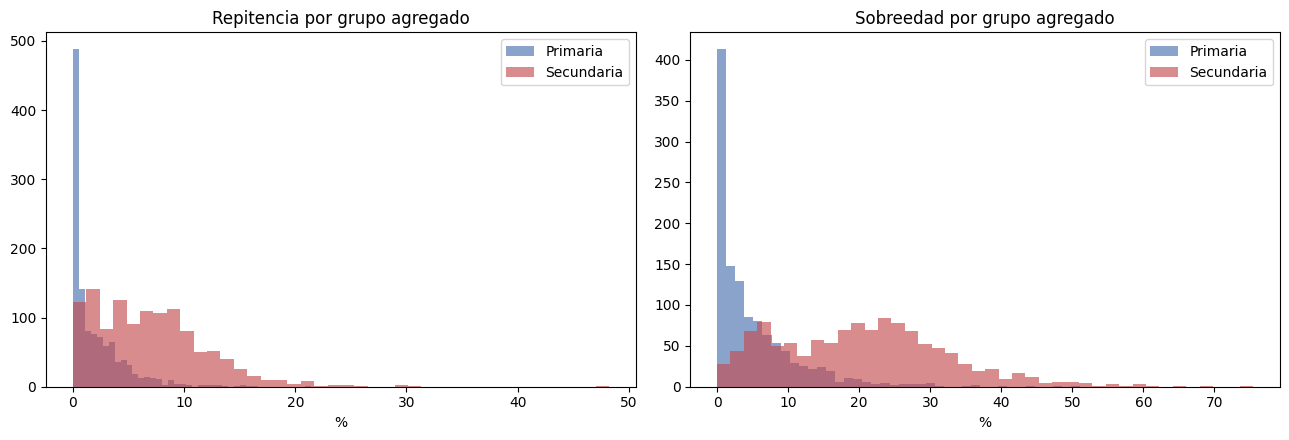

In [17]:
mat_eda = df_matriculas.copy()

for c in IDS:
    mat_eda[c] = mat_eda[c].str.strip()

nm = lambda cols: mat_eda[cols].apply(
    lambda s: pd.to_numeric(s.str.strip().replace("", np.nan), errors="coerce")
).fillna(0).sum(axis=1)

PRI_ = [str(i) for i in range(1, 7)]
SEC_ = [str(i) for i in range(7, 13)]

e = mat_eda[IDS].copy()

e["rep_pri"] = nm(["r_" + i for i in PRI_]) / nm(["_" + i for i in PRI_]).replace(0, np.nan) * 100
e["rep_sec"] = nm(["r_" + i for i in SEC_]) / nm(["_" + i for i in SEC_]).replace(0, np.nan) * 100
e["sob_pri"] = nm(["s_" + i for i in PRI_]) / nm(["_" + i for i in PRI_]).replace(0, np.nan) * 100
e["sob_sec"] = nm(["s_" + i for i in SEC_]) / nm(["_" + i for i in SEC_]).replace(0, np.nan) * 100

VARIABLES = ["rep_pri", "rep_sec", "sob_pri", "sob_sec"]

print("TASAS POR GRUPO AGREGADO (%)\n")
print(
    e[VARIABLES].describe().T[
        ["count", "mean", "50%", "max"]
    ].round(2).to_string()
)

print("\nPOR SECTOR Y ÁMBITO\n")
print(
    e.groupby(["sector", "ambito"])[VARIABLES]
    .mean()
    .round(2)
    .to_string()
)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for i, (p, s, t) in enumerate([
    ("rep_pri", "rep_sec", "Repitencia"),
    ("sob_pri", "sob_sec", "Sobreedad")
]):
    ax[i].hist(e[p].dropna(), bins=40, alpha=.65, label="Primaria", color="#4C72B0")
    ax[i].hist(e[s].dropna(), bins=40, alpha=.65, label="Secundaria", color="#C44E52")
    ax[i].set_title(f"{t} por grupo agregado")
    ax[i].set_xlabel("%")
    ax[i].legend()

plt.tight_layout()
plt.show()

> **`[ A REDACTAR ]`**  Qué muestran repitencia y sobreedad antes de cualquier modelo
>
> Tu lectura tiene que responder: *¿cómo se distribuyen?*, *¿dónde están los valores más
> altos?* y *¿qué diferencia hay entre primaria y secundaria?*
>
> Material que imprime la celda:
>
> - las tasas por nivel, calculadas sobre la base de Matrícula
> - los histogramas de repitencia y sobreedad
> - la comparación entre primaria y secundaria

>Estas tasas son **preliminares**: cortan primaria en 6° para todas las provincias y no aplican
>ningún mínimo de matrícula. En la sección 5.6 se recalculan respetando la estructura 6-6 / 7-5 de
>cada jurisdicción y descartando los grupos con menos de 30 alumnos, así que los valores finales
>difieren levemente de estos.

>La repitencia y la sobreedad son considerablemente mayores en secundaria que en primaria: la repitencia media es 6,95% frente a 1,99%, y la sobreedad 20,>44% frente a 5,11%. Los valores más altos se concentran principalmente en grupos estatales urbanos y rurales, mientras que el sector privado urbano >presenta las tasas más bajas.
>La distribución es asimétrica, con valores extremos de hasta 48,21% de repitencia y 75,45% de sobreedad en secundaria. En primaria, los máximos alcanzan >21,43% y 51,09%, respectivamente.
>Estos resultados son preliminares: se utilizó un corte fijo 1°–6° para primaria y 7°–12° para secundaria, sin excluir grupos con menos de 30 alumnos. En >la sección 5.6 se recalcularán las tasas respetando la estructura 6-6/7-5 de cada jurisdicción.

---
# 5. 🧹 Limpieza y preprocesamiento

*Punto 3 de la entrega: justificación de las tareas realizadas.*

**Limpieza** (5.1 y 5.2) y **preprocesamiento** (5.3 a 5.7).


## 5.1 Limpieza — la codificación de los faltantes






In [18]:
S = lambda d, c: d[c].astype("string").str.strip().replace("", np.nan)

N = lambda d, c: pd.to_numeric(S(d, c), errors="coerce")

def perfil_faltantes(d, nombre):
    cols = [c for c in d.columns if c not in IDS]
    valores = d[cols].apply(lambda s: s.astype("string").str.strip().replace("", np.nan))

    con_blanco = set(valores.columns[valores.isna().any()])
    con_cero = set(valores.columns[(valores == "0").any()])
    ambos = con_blanco & con_cero

    print(
        f"{nombre:<16} "
        f"vacias={int(valores.isna().sum().sum()):>7}  "
        f"ceros={int((valores == '0').sum().sum()):>7}  "
        f"columnas_con_AMBOS={len(ambos):>3}")

    return ambos

print("Columnas que usan blanco Y cero a la vez:\n")

a_car = perfil_faltantes(df_caracteristicas, "Características")
a_mat = perfil_faltantes(df_matriculas, "Matrícula")
a_tra = perfil_faltantes(df_trayectoria, "Trayectoria")

def revisar_blancos(d, denominador, resultado, nombre):
    riesgo = 0

    for i in map(str, range(1, 13)):
        base = N(d, denominador + i)
        valor = S(d, resultado + i)

        riesgo += int(((base > 0) & valor.isna()).sum())

    print(f"{nombre:<45} {riesgo:>5} casos con denominador > 0 y resultado en blanco")

    return riesgo


print("\nValidación de blancos según denominador:\n")

riesgo_rep = revisar_blancos(df_matriculas, "_", "r_", "Matrícula: repitentes")
riesgo_sob = revisar_blancos(df_matriculas, "_", "s_", "Matrícula: sobreedad")
riesgo_ssp = revisar_blancos(df_trayectoria,"inicial_", "ssp_", "Trayectoria: salidos sin pase")
riesgo_scp = revisar_blancos(df_trayectoria, "inicial_", "scp_", "Trayectoria: salidos con pase")
riesgo_prom = revisar_blancos(df_trayectoria, "ultimo_", "promovidos_", "Trayectoria: promovidos")
riesgo_prom_ex = revisar_blancos(df_trayectoria, "ultimo_", "promovidos_ex_", "Trayectoria: promovidos con examen")
riesgo_nopromo = revisar_blancos(df_trayectoria, "ultimo_", "nopromo_", "Trayectoria: no promovidos")

Columnas que usan blanco Y cero a la vez:

Características  vacias=  22371  ceros=      0  columnas_con_AMBOS=  0
Matrícula        vacias=  22264  ceros=  12223  columnas_con_AMBOS= 26
Trayectoria      vacias=  37496  ceros= 106780  columnas_con_AMBOS=263

Validación de blancos según denominador:

Matrícula: repitentes                             0 casos con denominador > 0 y resultado en blanco
Matrícula: sobreedad                           2009 casos con denominador > 0 y resultado en blanco
Trayectoria: salidos sin pase                     0 casos con denominador > 0 y resultado en blanco
Trayectoria: salidos con pase                     0 casos con denominador > 0 y resultado en blanco
Trayectoria: promovidos                           0 casos con denominador > 0 y resultado en blanco
Trayectoria: promovidos con examen                0 casos con denominador > 0 y resultado en blanco
Trayectoria: no promovidos                        0 casos con denominador > 0 y resultado en blanco


> **`[ A REDACTAR ]`**  Faltantes: diagnóstico y tratamiento
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - Qué encontré: los faltantes vienen como un espacio, no como vacío.
> - Cómo lo sé: 19.906 celdas; 0 columnas de Características mezclan blanco y 0;
>   en cambio Matrícula tiene 30 y Trayectoria 284 columnas que usan las dos.
> - Qué decidí: en Características el blanco es 0; en las otras dos es 'no aplica'.
> - Qué pasaba si no: imputar la media sobre el 26% del dataset inventaría datos.

El patrón de faltantes no es igual en las tres bases. En Características se detectaron 22.371 celdas vacías y ningún cero explícito, por lo que los blancos se interpretan como ausencia del recurso y pueden convertirse en cero para calcular coberturas. En Matrícula se encontraron 22.264 celdas vacías y 26 columnas que combinan blancos y ceros. La validación específica de repitentes no detectó casos con matrícula positiva y repitentes en blanco, por lo que en ese bloque el blanco puede interpretarse como no aplicable. En Trayectoria se identificaron 37.496 celdas vacías y 263 columnas que combinan blancos y ceros, por lo que no corresponde aplicar una única regla de imputación. El tratamiento deberá definirse por familia de variables y según sus denominadores.

## 5.2 Otros problemas de calidad


In [19]:
BASES = {
    "Características": df_caracteristicas,
    "Matrícula": df_matriculas,
    "Trayectoria": df_trayectoria,
}

def texto(s):
    return s.astype("string").str.strip().replace("", pd.NA)

def num(d, cols):
    return d[cols].apply(lambda s: pd.to_numeric(texto(s), errors="coerce"))

def keyset(d):
    claves = d[IDS].apply(texto).drop_duplicates()

    return set(map(tuple,claves.itertuples(index=False, name=None)))

print("DIMENSIONES Y DUPLICADOS\n")

for nombre, d in BASES.items():
    print(
        f"{nombre:<16} "
        f"filas={len(d):4} "
        f"columnas={d.shape[1]:3} "
        f"duplicados_fila={d.duplicated().sum():3} "
        f"duplicados_clave={d.duplicated(IDS).sum():3}"
    )


# Columnas completamente vacías en Características
cols_car = [c for c in df_caracteristicas.columns
    if c not in IDS
]

car_valores = df_caracteristicas[cols_car].apply(texto)

vacias_car = car_valores.columns[car_valores.isna().all()].tolist()

df_caracteristicas_limpio = df_caracteristicas.drop(columns=vacias_car)

print(
    f"\nCaracterísticas: "
    f"{df_caracteristicas.shape[1]} -> "
    f"{df_caracteristicas_limpio.shape[1]} columnas"
)

# Departamentos enmascarados
print("\nFILAS CON DEPARTAMENTO 'ENMASCARADO'")

for nombre, d in BASES.items():
    cantidad = texto(d["departamento"]).eq("Enmascarado").sum()
    print(f"{nombre:<16} {cantidad:3} filas")

# Controles de coherencia
def incumplimientos(d, columnas_a, columnas_b):
    a = num(d, columnas_a).to_numpy(dtype=float)
    b = num(d, columnas_b).to_numpy(dtype=float)

    validos = (np.isfinite(a) & np.isfinite(b))

    return int(((a > b) & validos).sum())


AA = [str(i) for i in range(1, 13)]

print("\nCONTROLES DE COHERENCIA")

print("Matrícula: repitentes > matrícula:",incumplimientos(df_matriculas, [f"r_{i}" for i in AA], [f"_{i}" for i in AA]))

print("Matrícula: sobreedad > matrícula:", incumplimientos(df_matriculas,[f"s_{i}" for i in AA], [f"_{i}" for i in AA]))

print("Trayectoria: salidos sin pase > inicial:", incumplimientos(df_trayectoria, [f"ssp_{i}" for i in AA], [f"inicial_{i}" for i in AA]))

print("Trayectoria: salidos con pase > inicial:", incumplimientos(df_trayectoria, [f"scp_{i}" for i in AA], [f"inicial_{i}" for i in AA]))

print("Trayectoria: promovidos > último:", incumplimientos(df_trayectoria, [f"promovidos_{i}" for i in AA], [f"ultimo_{i}" for i in AA]))

print("Trayectoria: no promovidos > último:", incumplimientos(df_trayectoria, [f"nopromo_{i}" for i in AA], [f"ultimo_{i}" for i in AA]))


# Valores negativos
print("\nVALORES NEGATIVOS")

for nombre, d in BASES.items():
    cols = [c for c in d.columns
        if c not in IDS
    ]

    valores = num(d, cols)
    negativos = int((valores < 0).sum().sum())

    print(f"{nombre:<16} {negativos}")


# Consistencia de categorías
print("\nCONSISTENCIA DE CATEGORÍAS")

for columna in ["sector", "ambito"]:
    categorias = {nombre: set(texto(d[columna]).dropna().unique())
        for nombre, d in BASES.items()
    }

    consistentes = len({frozenset(valores)
        for valores in categorias.values()
    }) == 1

    print(f"{columna:<10} - consistentes: {consistentes}"
    )
    print(categorias)


# Auditoría de claves entre bases
print("\nAUDITORÍA DE CLAVES")

for nombre, d in BASES.items():
    print(
        f"{nombre:<16} - claves únicas: {len(keyset(d)):4}"
    )


pares = [
    ("Características", "Matrícula"),
    ("Características", "Trayectoria"),
    ("Matrícula", "Trayectoria")
]

for base_a, base_b in pares:
    claves_a = keyset(BASES[base_a])
    claves_b = keyset(BASES[base_b])

    print(
        f"{base_a} vs {base_b}: "
        f"comunes={len(claves_a & claves_b):4} | "
        f"solo {base_a}={len(claves_a - claves_b):3} | "
        f"solo {base_b}={len(claves_b - claves_a):3}"
    )



DIMENSIONES Y DUPLICADOS

Características  filas=1216 columnas= 66 duplicados_fila=  0 duplicados_clave=  0
Matrícula        filas=1216 columnas=104 duplicados_fila=  0 duplicados_clave=  0
Trayectoria      filas=1209 columnas=288 duplicados_fila=  0 duplicados_clave=  0

Características: 66 -> 64 columnas

FILAS CON DEPARTAMENTO 'ENMASCARADO'
Características   66 filas
Matrícula         66 filas
Trayectoria       65 filas

CONTROLES DE COHERENCIA
Matrícula: repitentes > matrícula: 0
Matrícula: sobreedad > matrícula: 0
Trayectoria: salidos sin pase > inicial: 0
Trayectoria: salidos con pase > inicial: 0
Trayectoria: promovidos > último: 0
Trayectoria: no promovidos > último: 0

VALORES NEGATIVOS
Características  0
Matrícula        0
Trayectoria      0

CONSISTENCIA DE CATEGORÍAS
sector     - consistentes: True
{'Características': {'Estatal', 'Privado'}, 'Matrícula': {'Estatal', 'Privado'}, 'Trayectoria': {'Estatal', 'Privado'}}
ambito     - consistentes: True
{'Características': {'Urba

In [20]:
print("\nCOMPARACIÓN DE LOCALIZACIÓN")

localizacion = (
    df_caracteristicas[IDS + ["localizacion"]]
    .merge(
        df_matriculas[IDS + ["localizacion"]],
        on=IDS,
        how="outer",
        suffixes=("_car", "_mat"),
        indicator=True,
        validate="one_to_one"
    )
)

localizacion["localizacion_car"] = pd.to_numeric(
    localizacion["localizacion_car"],
    errors="coerce"
)

localizacion["localizacion_mat"] = pd.to_numeric(
    localizacion["localizacion_mat"],
    errors="coerce"
)

localizacion["diferencia"] = (
    localizacion["localizacion_mat"]
    - localizacion["localizacion_car"]
)

print(
    localizacion["_merge"]
    .value_counts()
    .to_string()
)

ambas = localizacion["_merge"].eq("both")

print(
    "Claves con distinta localizacion:",
    int(
        (
            ambas
            & localizacion["diferencia"].ne(0)
        ).sum()
    )
)

print(
    "Total Características:",
    localizacion["localizacion_car"].sum()
)

print(
    "Total Matrícula:",
    localizacion["localizacion_mat"].sum()
)


COMPARACIÓN DE LOCALIZACIÓN
_merge
both          1216
left_only        0
right_only       0
Claves con distinta localizacion: 116
Total Características: 50591
Total Matrícula: 50327


In [21]:
diferencias_loc = localizacion[
    localizacion["_merge"].eq("both")
    & localizacion["diferencia"].ne(0)
].copy()

print(diferencias_loc["diferencia"].describe().round(2))

print(
    diferencias_loc[
        IDS
        + [
            "localizacion_car",
            "localizacion_mat",
            "diferencia"
        ]
    ]
    .sort_values("diferencia")
    .head(10)
    .to_string(index=False)
)

count    116.00
mean      -2.28
std        2.20
min      -11.00
25%       -3.00
50%       -1.00
75%       -1.00
max       -1.00
Name: diferencia, dtype: float64
          provincia        departamento  sector ambito  localizacion_car  localizacion_mat  diferencia
       Buenos Aires            LA PLATA Privado Urbano               317               306         -11
       Buenos Aires          SAN MIGUEL Privado Urbano               146               136         -10
       Buenos Aires            LA PLATA Estatal Urbano               355               346          -9
Santiago del Estero              ROBLES Estatal Urbano                31                22          -9
Santiago del Estero              LORETO Estatal  Rural                65                56          -9
       Buenos Aires          LA MATANZA Estatal Urbano               615               607          -8
       Buenos Aires     LOMAS DE ZAMORA Privado Urbano               254               247          -7
Santiago del Es

> **`[ A REDACTAR ]`**  Calidad de los datos
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - 3 columnas sin un solo registro en todo el país -> descartar.
> - 68 filas con departamento 'Enmascarado' -> conservar (es secreto estadístico, no un error).
> - Controles de coherencia: 0 repitentes mayores a su matrícula, 0 valores negativos,
>   0 salidos sin pase mayores a la matrícula inicial.
> - Duplicados: 0 en las tres bases. Categóricas: sector y ámbito idénticos entre bases.
> - Qué pasaba si no: borrar los enmascarados cuesta ~1.000 establecimientos y sesga la
>   muestra justo contra los departamentos chicos y rurales.
> - Los controles que dan limpio también se reportan: son los que explican que después
>   la integración cruce 1217 de 1217 sin correcciones manuales.

>Las bases de Características y Matrícula comparten las 1.216 claves de integración, pero presentan diferencias en la cantidad de establecimientos >asociados a cada grupo. En 116 grupos, Matrícula registra menos establecimientos que Características, con una diferencia media de 2,28 establecimientos y >una diferencia máxima de 11. En ningún caso Matrícula supera a Características.

>Esta diferencia no impide vincular las bases, pero indica que localizacion no debe utilizarse como un denominador universal. Para las coberturas de >infraestructura se utilizará la localizacion de Características, mientras que los análisis propios de Matrícula conservarán su denominador. Las tasas de >repitencia y sobreedad se calcularán sobre matrícula de alumnos, no sobre cantidad de establecimientos.

## 5.3 Transformaciones — cobertura vs. densidad






In [22]:
feat_car = [c for c in df_caracteristicas.columns
    if c not in IDS
]

raw_car = (df_caracteristicas[feat_car].astype("string").apply(lambda s: s.str.strip().replace("", np.nan)))

vacias_car = raw_car.columns[raw_car.isna().all()].tolist()

X = (raw_car.apply(pd.to_numeric, errors="coerce").fillna(0).drop(columns=vacias_car))

In [23]:
base = pd.concat([df_caracteristicas[IDS], X], axis=1)

base["depto_enmascarado"] = (base["departamento"] == "Enmascarado").astype(int)

L = pd.to_numeric(base["localizacion"], errors="coerce")

medidas = [c for c in X.columns
    if c != "localizacion"
]

rate = base[medidas].div(L, axis=0)

cobertura = [
    c for c in medidas
    if rate[c].max() <= 1.0001
]

densidad = [
    c for c in medidas
    if rate[c].max() > 1.0001
]

print(
    f"COBERTURA "
    f"(proporción de establecimientos, 0-1): "
    f"{len(cobertura)} variables"
)

print(
    f"DENSIDAD "
    f"(aparatos por establecimiento): "
    f"{len(densidad)} variables\n"
)

print("Densidades más extremas:")
print(
    rate[densidad]
    .max()
    .sort_values(ascending=False)
    .head(5)
    .round(2)
    .to_string()
)

T = pd.DataFrame(index=base.index)

for c in cobertura:
    T["cob_" + c] = rate[c].clip(0, 1)

if densidad:
    print("Densidades más extremas:")
    print(
        rate[densidad]
        .max()
        .sort_values(ascending=False)
        .head(5)
        .round(2)
        .to_string()
    )
else:
    print(
        "No se detectaron variables de densidad "
        "en Características 2024."
    )

T["log_localizacion"] = np.log1p(L)

print(f"Variables transformadas generadas: {T.shape[1]}")


COBERTURA (proporción de establecimientos, 0-1): 59 variables
DENSIDAD (aparatos por establecimiento): 0 variables

Densidades más extremas:
Series([], )
No se detectaron variables de densidad en Características 2024.
Variables transformadas generadas: 60


In [24]:
L = pd.to_numeric(
    df_caracteristicas["localizacion"],
    errors="coerce"
)

for c in [
    "equipamientoestablecimientotelevisor",
    "equipamientoestablecimientoimpresora",
    "equipamientoestablecimientosistemamultimediaocañón"
]:
    if c in df_caracteristicas.columns:
        valores = pd.to_numeric(
            df_caracteristicas[c],
            errors="coerce"
        )

        tasa = valores / L
        idx = tasa.idxmax()

        print(f"\n{c}")
        print(f"Máximo bruto: {valores.max():.2f}")
        print(f"Máximo relativo: {tasa.max():.2f}")
        print(f"Localizacion en esa fila: {L.loc[idx]:.0f}")
        print(f"Valor en esa fila: {valores.loc[idx]:.0f}")


equipamientoestablecimientotelevisor
Máximo bruto: 550.00
Máximo relativo: 1.00
Localizacion en esa fila: 8
Valor en esa fila: 8

equipamientoestablecimientoimpresora
Máximo bruto: 635.00
Máximo relativo: 1.00
Localizacion en esa fila: 9
Valor en esa fila: 9

equipamientoestablecimientosistemamultimediaocañón
Máximo bruto: 623.00
Máximo relativo: 1.00
Localizacion en esa fila: 6
Valor en esa fila: 6


> **`[ A REDACTAR ]`**  Transformaciones: cobertura vs. densidad
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - Qué encontré: las columnas no miden lo mismo (unas cuentan escuelas, otras aparatos).
> - Cómo lo sé: 42 nunca superan Localizacion, 17 sí · máximo 39,78 TVs por establecimiento.
> - Qué decidí: tasa 0-1 para cobertura, aparatos por escuela + log1p para densidad.
> - Qué pasaba si no: Localizacion va de 1 a 704, así que la distancia euclídea queda
>   dominada por el tamaño y K-Means separa grandes de chicos, no perfiles.
>   Y sin log1p la asimetría media es 6,55 (con log1p baja a 2,95).
> - Detalle: el tamaño no se tira, entra como una variable más.

>Las 59 variables de medición se comportan como coberturas de establecimientos. Incluso las variables de equipamiento alcanzan como máximo el valor de >localizacion, lo que indica que cuentan establecimientos que disponen del recurso y no unidades físicas de equipamiento. Por eso, todas las variables se >transforman como proporciones entre 0 y 1. El tamaño del grupo se conserva por separado mediante log_localizacion.

## 5.4 Selección de variables — redundancia estructural

> **`[ A REDACTAR ]`**  Selección de variables
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - Qué encontré: dependencias lineales exactas por el diseño del formulario.
> - Cómo lo sé: las 4 modalidades de gestión suman el total en el 100,0% de las filas;
>   cooperadora son 3 categorías exhaustivas; 2 variables con std < 0,02.
> - Qué decidí: sacar el total (no las modalidades), una categoría de cooperadora,
>   y las dos casi constantes. 60 -> 56.
> - Qué pasaba si no: la matriz de covarianza queda singular, PCA se rompe y
>   K-Means le da peso doble a esa información.
> - Criterio: se conserva lo que tiene más información (las modalidades dicen qué tipo,
>   el total solo dice sí/no).




In [25]:
quitar = []

# (a) Gestión escolar: las 4 modalidades deberían sumar el total
total  = "cob_sistemadegestiónescolarsi"
partes = [c for c in T.columns
          if c.startswith("cob_sistemadegestión") and c != total]

coincide = np.isclose(T[partes].sum(axis=1), T[total]).mean()
print(f"(a) suma({len(partes)} modalidades de gestión) == total en {coincide*100:.1f}% de las filas")
if coincide > 0.999:
    print("    -> dependencia lineal EXACTA: se quita el total y se conservan las modalidades.")
    quitar.append(total)
else:
    print("    -> NO es exacta: se conserva el total.")

# (b) Cooperadora: Con / Sin / No debería ser una partición exhaustiva
coop = [c for c in T.columns if c.startswith("cob_cooperadora")]
suma_coop = T[coop].sum(axis=1)
print(f"\n(b) Cooperadora: {len(coop)} categorías, suman 1 en "
      f"{np.isclose(suma_coop, 1).mean()*100:.1f}% de las filas")
if np.isclose(suma_coop, 1).mean() > 0.999:
    print("    -> partición exhaustiva: se quita 1 (trampa de la dummy).")
    quitar.append("cob_cooperadorano")
else:
    print("    -> NO es exhaustiva: se conservan las 3.")

# (c) Casi constantes
cte = [c for c in T.columns if T[c].std() < 0.02]
print(f"\n(c) Casi constantes (std < 0.02): {len(cte)}")
for c in cte:
    print(f"    - {c[4:]}  (std={T[c].std():.4f})")
quitar += cte

T_sel = T.drop(columns=[c for c in dict.fromkeys(quitar) if c in T.columns])
print(f"\nSelección: {T.shape[1]} -> {T_sel.shape[1]} variables")


(a) suma(4 modalidades de gestión) == total en 100.0% de las filas
    -> dependencia lineal EXACTA: se quita el total y se conservan las modalidades.

(b) Cooperadora: 3 categorías, suman 1 en 92.7% de las filas
    -> NO es exhaustiva: se conservan las 3.

(c) Casi constantes (std < 0.02): 2
    - electricidadgeneradoreólico  (std=0.0060)
    - electricidadgeneradorhidráulico  (std=0.0084)

Selección: 60 -> 57 variables


## 5.5 Creación de nuevas variables

> **`[ A REDACTAR ]`**  Creación de nuevas variables
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - Tres tipos: resúmenes de bloque, diferencias, y diversidad/proporciones.
> - Qué aporta cada uno y por qué no alcanzaba con las columnas originales.
> - El caso más claro: brecha_admin_aula da +16,8 puntos promedio. Ninguna de las dos
>   columnas por separado dice eso: una mide administración, otra aulas,
>   la diferencia dice a dónde se priorizó.




In [26]:
Nv = pd.DataFrame(index=base.index)
pick = lambda p: [c for c in T.columns if c.startswith(p)]
div  = lambda a, b: (a / b.replace(0, np.nan)).fillna(0)     # razón; 0 si el denominador es 0

Nv["idx_conectividad_espacios"] = T[pick("cob_espaciosconconexión")].mean(axis=1)
Nv["idx_equipamiento_estab"]    = T[pick("cob_equipamientoestablecimiento")].mean(axis=1)
Nv["idx_equipamiento_biblio"]   = T[pick("cob_equipamientobiblioteca")].mean(axis=1)

Nv["brecha_admin_aula"] = (T["cob_espaciosconconexióneneláreadeadministración"] - T["cob_espaciosconconexiónenlasaulas"])

Nv["lab_exclusivo_sobre_disponible"] = div(T["cob_laboratoriofuncionaesespacioexclusivosi"], T["cob_disponedesalaolaboratoriodeinformáticasi"])
Nv["biblio_exclusiva_sobre_disponible"] = div(T["cob_bibliotecafuncionaesespacioexclusivosi"], T["cob_bibliotecadisponedealmenosunasi"])

tipos = pick("cob_internettipodeconexión")
fija  = ["cob_internettipodeconexiónadsl", "cob_internettipodeconexióncablemódem"]
Nv["conexion_fija_sobre_total"] = div(T[fija].sum(axis=1), T[tipos].sum(axis=1))

serv = pick("cob_internettipodeservicio")
Nv["internet_pago_sobre_total"] = div(T["cob_internettipodeserviciopago"], T[serv].sum(axis=1))

alt = [c for c in pick("cob_electricidad")
       if not c.endswith(("electricidadsi", "electricidadredpública"))]
Nv["sin_red_publica"]     = (1 - T["cob_electricidadredpública"]).clip(0, 1)
Nv["energia_alternativa"] = T[alt].sum(axis=1).clip(0, 1)

Nv["es_privado"] = (base["sector"] == "Privado").astype(int)
Nv["es_urbano"]  = (base["ambito"] == "Urbano").astype(int)

print(Nv.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
print("\nCorrelación con el tamaño del grupo (log_localizacion):")
print(Nv.corrwith(T["log_localizacion"]).round(2).to_string())


                                       mean       std       min       max
idx_conectividad_espacios          0.466236  0.192537       0.0       1.0
idx_equipamiento_estab             0.444162  0.117338  0.037634  0.763889
idx_equipamiento_biblio            0.120496  0.079454       0.0  0.511111
brecha_admin_aula                  0.186891  0.300405      -0.6       1.0
lab_exclusivo_sobre_disponible     0.559876  0.321649       0.0       1.0
biblio_exclusiva_sobre_disponible  0.598114  0.226278       0.0       1.0
conexion_fija_sobre_total          0.399696  0.202383       0.0       1.0
internet_pago_sobre_total           0.28164  0.370222       0.0       1.0
sin_red_publica                     0.05714  0.134432       0.0       1.0
energia_alternativa                0.095394  0.193809       0.0       1.0
es_privado                         0.260691  0.439192       0.0       1.0
es_urbano                          0.588816  0.492251       0.0       1.0

Correlación con el tamaño del grupo (

## 5.6 Integración — los indicadores por departamento

> **`[ A REDACTAR ]`**  Integración de los datasets
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - Problema 1 - granularidad: no existe cueanexo, la clave es prov x depto x sector x ámbito.
> - Problema 2 - estructura: 12 provincias 6-6 y 12 7-5; cortar igual para todas mezcla niveles.
> - Problema 3 - denominadores: 8.597.492 vs 8.651.276 (0,6% de diferencia),
>   cada tasa usa el de su propia base.
> - Umbral: debajo de 30 alumnos la tasa es ruido (1 repitente sobre 5 da 20%). 36 filas a NaN.
> - Evidencia de que salió bien: 1217 -> 1217, sin duplicar, 0 sin match.




In [27]:
HOJA_PREVIA = "2022"   # el target sale de Matrícula 2024 (= "tasa 2023" oficial) -> el rezago es la hoja 2022

def repitencia_provincial(hoja):
    d = pd.read_excel(RUTAS["repitencia_ofi"], sheet_name=hoja, header=None)
    es_prov = d[1].isin(["6-6", "7-5"])            # las filas de provincia son las que traen estructura
    out = pd.DataFrame({"pn": d.loc[es_prov, 0].map(norm),
                        "estructura": d.loc[es_prov, 1],
                        "pri": pd.to_numeric(d.loc[es_prov, 2], errors="coerce"),
                        "sec": pd.to_numeric(d.loc[es_prov, 10], errors="coerce")})
    return out[~out.pn.isin(["CONURBANO", "RESTO DE BS AS"])].set_index("pn")

of_2023 = repitencia_provincial("2023")            # solo para validar el cálculo (5.7)
previa  = repitencia_provincial(HOJA_PREVIA)       # rezago: sí puede usarse como variable
previa.loc[previa.sec == 0, "sec"] = np.nan        # Santa Cruz informa 0 en secundaria: es dato no informado

estructura = of_2023.estructura.to_dict()
oficial    = {p: (r.pri, r.sec) for p, r in of_2023.iterrows()}

print(pd.Series(estructura).value_counts().to_string())
print(f"\nProvincias 6-6: {[p for p, v in estructura.items() if v == '6-6'][:4]} ...")
print(f"Provincias 7-5: {[p for p, v in estructura.items() if v == '7-5'][:4]} ...")


6-6    12
7-5    12

Provincias 6-6: ['BUENOS AIRES', 'CATAMARCA', 'CHUBUT', 'CORDOBA'] ...
Provincias 7-5: ['CHACO', 'CIUDAD DE BUENOS AIRES', 'JUJUY', 'LA RIOJA'] ...


In [28]:
df_matriculas["pn"]  = df_matriculas.provincia.map(norm)
df_trayectoria["pn"] = df_trayectoria.provincia.map(norm)
assert set(df_matriculas.pn) <= set(estructura), "hay provincias sin estructura educativa"

def suma(d, cols):
    return d[cols].apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1).astype(float)

bloques = []
for pn in sorted(set(df_matriculas.pn)):
    corte = 6 if estructura[pn] == "6-6" else 7
    PRI = [str(i) for i in range(1, corte + 1)]
    SEC = [str(i) for i in range(corte + 1, 13)]
    gm, gt = df_matriculas[df_matriculas.pn == pn], df_trayectoria[df_trayectoria.pn == pn]
    f = gm[IDS].copy()
    f["mat_pri"] = suma(gm, ["_" + i for i in PRI]);  f["mat_sec"] = suma(gm, ["_" + i for i in SEC])
    f["rep_pri"] = suma(gm, ["r_" + i for i in PRI]); f["rep_sec"] = suma(gm, ["r_" + i for i in SEC])
    f["sob_pri"] = suma(gm, ["s_" + i for i in PRI]); f["sob_sec"] = suma(gm, ["s_" + i for i in SEC])
    t = gt[IDS].copy()
    t["ini_pri"] = suma(gt, ["inicial_" + i for i in PRI]); t["ini_sec"] = suma(gt, ["inicial_" + i for i in SEC])
    t["ssp_pri"] = suma(gt, ["ssp_" + i for i in PRI]);     t["ssp_sec"] = suma(gt, ["ssp_" + i for i in SEC])
    bloques.append(f.merge(t, on=IDS, how="left", indicator=True))

IND = pd.concat(bloques, ignore_index=True)
IND["pn"] = IND.provincia.map(norm)

# Evidencia real del cruce con Trayectoria
print(f"Grupos de Matrícula: {len(IND)} | con Trayectoria: {(IND._merge == 'both').sum()} "
      f"| sin Trayectoria: {(IND._merge != 'both').sum()}")
print(f"Filas de Trayectoria que no cruzaron con ningún grupo: "
      f"{len(df_trayectoria) - (IND._merge == 'both').sum()}")
IND = IND.drop(columns="_merge")

MIN_MATRICULA = 30   # debajo de esto una tasa es ruido
tasa = lambda a, b: a / b.where(b >= MIN_MATRICULA) * 100

IND["tasa_repitencia_pri"] = tasa(IND.rep_pri, IND.mat_pri)
IND["tasa_repitencia_sec"] = tasa(IND.rep_sec, IND.mat_sec)
IND["tasa_sobreedad_pri"]  = tasa(IND.sob_pri, IND.mat_pri)
IND["tasa_sobreedad_sec"]  = tasa(IND.sob_sec, IND.mat_sec)
IND["tasa_ssp_pri"]        = tasa(IND.ssp_pri, IND.ini_pri)
IND["tasa_ssp_sec"]        = tasa(IND.ssp_sec, IND.ini_sec)

# Provincia que informa 0 repitentes en TODA su secundaria (Santa Cruz): no es un 0 real
sin_dato = IND.groupby("pn").rep_sec.transform("sum") == 0
IND.loc[sin_dato, "tasa_repitencia_sec"] = np.nan
print(f"Grupos con repitencia secundaria puesta en NaN por provincia sin dato: {int(sin_dato.sum())} "
      f"({sorted(IND.loc[sin_dato, 'provincia'].unique())})")

# Variables provinciales (se agregan a las features en 6.1)
IND["prov_estructura_7_5"] = IND.pn.map(lambda p: int(estructura[p] == "7-5"))
IND["prov_rep_pri_prev"]   = IND.pn.map(previa.pri)
IND["prov_rep_sec_prev"]   = IND.pn.map(previa.sec)
PROV  = ["prov_estructura_7_5", "prov_rep_pri_prev", "prov_rep_sec_prev"]
TASAS = [c for c in IND.columns if c.startswith("tasa_")]

print(f"\nUmbral aplicado: {MIN_MATRICULA} alumnos (debajo la tasa queda NaN por inestable)\n")
for c in TASAS:
    print(f"  {c:<22} media {IND[c].mean():>6.2f}%   válidas {IND[c].notna().sum():>5}/{len(IND)}")


Grupos de Matrícula: 1216 | con Trayectoria: 1207 | sin Trayectoria: 9
Filas de Trayectoria que no cruzaron con ningún grupo: 2
Grupos con repitencia secundaria puesta en NaN por provincia sin dato: 15 (['Santa Cruz'])

Umbral aplicado: 30 alumnos (debajo la tasa queda NaN por inestable)

  tasa_repitencia_pri    media   1.98%   válidas  1196/1216
  tasa_repitencia_sec    media   7.60%   válidas  1168/1216
  tasa_sobreedad_pri     media   5.24%   válidas  1196/1216
  tasa_sobreedad_sec     media  21.85%   válidas  1182/1216
  tasa_ssp_pri           media   0.21%   válidas  1197/1216
  tasa_ssp_sec           media   1.85%   válidas  1180/1216


## 5.7 Validación del cálculo contra las cifras oficiales



In [29]:
agg = IND.groupby("pn")[["rep_pri", "mat_pri", "rep_sec", "mat_sec"]].sum()
agg["calculada_pri"] = agg.rep_pri / agg.mat_pri * 100
agg["calculada_sec"] = agg.rep_sec / agg.mat_sec * 100
agg["oficial_pri"] = agg.index.map(lambda p: oficial[p][0])
agg["oficial_sec"] = agg.index.map(lambda p: oficial[p][1])

print(agg[["calculada_pri", "oficial_pri", "calculada_sec", "oficial_sec"]].round(2).to_string())

# Provincias sin dato real en secundaria: el oficial informa 0 y el relevamiento también (0 repitentes)
sin_dato = agg.index[(agg.oficial_sec == 0) & (agg.rep_sec == 0)]
ok = agg.drop(index=sin_dato)

print(f"\nCorrelación PRIMARIA   : r = {agg.calculada_pri.corr(agg.oficial_pri):.3f}   (n={len(agg)})")
print(f"Correlación SECUNDARIA : r = {agg.calculada_sec.corr(agg.oficial_sec):.3f}   (n={len(agg)})")
print(f"Correlación SECUNDARIA sin {', '.join(sin_dato)}: "
      f"r = {ok.calculada_sec.corr(ok.oficial_sec):.3f}   (n={len(ok)})")

# La correlación mide el orden entre provincias; la diferencia mide el nivel
for nivel, d in [("pri", agg), ("sec", ok)]:
    dif = (d[f"calculada_{nivel}"] - d[f"oficial_{nivel}"]).abs()
    print(f"Diferencia absoluta {nivel.upper()}: media {dif.mean():.2f} pp | "
          f"máxima {dif.max():.2f} pp ({dif.idxmax()})")

print(f"\nProvincias sin dato en secundaria: {list(sin_dato)}")
print("-> informan 0 repitentes en el relevamiento y 0,0 en el archivo oficial: no es un 0 real,")
print("   por eso se excluyen de la comparación y su tasa secundaria queda en NaN en IND.")


                        calculada_pri  oficial_pri  calculada_sec  oficial_sec
pn                                                                            
BUENOS AIRES                     2.62         2.55           6.29         6.26
CATAMARCA                        1.31         1.29           5.91         5.75
CHACO                            0.98         0.98           8.57         8.43
CHUBUT                           0.14         0.14           7.10         7.08
CIUDAD DE BUENOS AIRES           0.94         0.91           4.56         4.51
CORDOBA                          0.50         0.50           6.68         6.65
CORRIENTES                       5.96         5.88           9.62         9.63
ENTRE RIOS                       4.27         4.22          10.72        10.65
FORMOSA                          0.77         0.76          10.64        10.64
JUJUY                            0.05         0.05          10.65        10.65
LA PAMPA                         0.33         0.32  

> **`[ A REDACTAR ]`**  Validación contra las cifras oficiales
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - Por qué no alcanza con calcular el indicador: hay que probar que está bien calculado.
> - El método: agregar a nivel provincia y comparar contra la tasa oficial del Ministerio.
> - Resultado: r = 0,984 en primaria, r = 0,856 en secundaria.
> - El hallazgo intermedio: secundaria daba 0,428 hasta detectar que Santa Cruz figura
>   con 0,0 en el archivo oficial, que es un faltante mal codificado, no un valor real.


>La tasa de repitencia calculada a partir de Matrícula 2024 reproduce la tasa oficial del Ministerio casi sin diferencia. A nivel provincia, la >correlación es r = 1,000 en primaria y en secundaria (0,999 sin Santa Cruz). La diferencia absoluta media es de 0,02 pp en primaria y 0,07 pp en >secundaria, con un máximo de 0,22 pp (Misiones).

>Agregué los repitentes y la matrícula de cada grupo a nivel provincia, con la estructura 6-6 o 7-5 de cada una, y los comparé con la hoja 2023 del >archivo oficial. Esa tasa se construye con los repitentes del relevamiento 2024, los mismos que usamos, y las diferencias menores a 0,25 pp se explican >porque el oficial divide por la matrícula del año anterior.

>Santa Cruz figura con 0,0 en secundaria en el archivo oficial, y también con 0 repitentes en el relevamiento. No es un valor real sino un dato no >informado. Lo excluí de la comparación y dejé su repitencia secundaria en NaN, para que el modelo no aprenda 15 grupos con valor 0 artificial.

>Sin esta prueba no habría forma de saber si el indicador estaba bien calculado, y un error en el corte entre primaria y secundaria o en el denominador contaminaría todo el análisis. Con Santa Cruz incluida como 0, el modelo habría tratado un dato faltante como una escuela sin repitentes.

---
# 6. 📋 Descripción del dataset limpio

*Punto 4 de la entrega.*


## 6.1 El dataset resultante


In [30]:
FEATURES_INFRA = list(T_sel.columns) + list(Nv.columns)
FEATURES       = FEATURES_INFRA + PROV
INFRA = pd.concat([base[IDS + ["depto_enmascarado", "localizacion"]], T_sel, Nv], axis=1)

n0 = len(INFRA)
df_limpio = INFRA.merge(IND[IDS + ["mat_pri", "mat_sec"] + PROV + TASAS],
                        on=IDS, how="left", validate="one_to_one")

enm   = df_limpio.departamento.eq("Enmascarado")
n_dep = df_limpio.loc[~enm, ["provincia", "departamento"]].drop_duplicates().shape[0]

print("=" * 68)
print("DATASET LIMPIO")
print("=" * 68)
print(f"Filas antes -> después de integrar : {n0} -> {len(df_limpio)}  (sin duplicación)")
print(f"Dimensiones                        : {df_limpio.shape[0]} x {df_limpio.shape[1]}")
print(f"  features de infraestructura      : {len(FEATURES_INFRA)}")
print(f"  features provinciales            : {len(PROV)}")
print(f"  indicadores por grupo            : {len(TASAS)}")
print(f"Establecimientos representados     : {df_limpio.localizacion.sum():,.0f}")
print(f"Cobertura                          : {df_limpio.provincia.nunique()} provincias, "
      f"{n_dep} departamentos + {int(enm.sum())} grupos con departamento enmascarado")
faltan = df_limpio[FEATURES].isna().sum()
print(f"Features con faltantes             : {faltan[faltan > 0].to_dict()}")
print(f"Filas con target disponible        : primaria {df_limpio.tasa_repitencia_pri.notna().sum()} | "
      f"secundaria {df_limpio.tasa_repitencia_sec.notna().sum()}")
print()
print("Distribución por sector y ámbito:")
print(pd.crosstab(df_limpio.sector, df_limpio.ambito, margins=True).to_string())
print()
print(f"Valores DISTINTOS de repitencia primaria: {df_limpio.tasa_repitencia_pri.round(4).nunique()}")
print("(con el indicador provincial habrían sido solo 24, uno por provincia)")


DATASET LIMPIO
Filas antes -> después de integrar : 1216 -> 1216  (sin duplicación)
Dimensiones                        : 1216 x 86
  features de infraestructura      : 69
  features provinciales            : 3
  indicadores por grupo            : 6
Establecimientos representados     : 50,591
Cobertura                          : 24 provincias, 513 departamentos + 66 grupos con departamento enmascarado
Features con faltantes             : {'prov_rep_sec_prev': 15}
Filas con target disponible        : primaria 1196 | secundaria 1168

Distribución por sector y ámbito:
ambito   Rural  Urbano   All
sector                      
Estatal    454     445   899
Privado     46     271   317
All        500     716  1216

Valores DISTINTOS de repitencia primaria: 975
(con el indicador provincial habrían sido solo 24, uno por provincia)


In [31]:
df_limpio.to_csv("dataset_limpio.csv", index=False, encoding="utf-8")
with open("features_modelo.json", "w", encoding="utf-8") as fh:
    json.dump({"features_infraestructura": FEATURES_INFRA,
               "features_provinciales": PROV,
               "indicadores_por_grupo": TASAS,
               "identificacion": IDS,
               "umbral_matricula": MIN_MATRICULA,
               "hoja_rezago_provincial": HOJA_PREVIA}, fh, ensure_ascii=False, indent=1)

print("Archivos generados:")
print("   - dataset_limpio.csv   ", df_limpio.shape)
print("   - features_modelo.json ", len(FEATURES), "features /", len(TASAS), "indicadores")
df_limpio.head()


Archivos generados:
   - dataset_limpio.csv    (1216, 86)
   - features_modelo.json  72 features / 6 indicadores


,provincia,departamento,sector,ambito,depto_enmascarado,localizacion,cob_electricidadsi,cob_electricidadredpública,cob_electricidadgrupoelectrógeno,cob_electricidadpanelfotovoltaicosolar,cob_electricidadotro,cob_equipamientoestablecimientotelevisor,cob_equipamientoestablecimientosistemamultimediaocañón,cob_equipamientoestablecimientoscanner,cob_equipamientoestablecimientowebcam,cob_equipamientoestablecimientoreproductordecd,cob_equipamientoestablecimientoreproductordedvd,cob_equipamientoestablecimientoimpresora,cob_equipamientoestablecimientoequipoemisorderadioamfm,cob_equipamientoestablecimientoservidorparausoescolar,cob_equipamientoestablecimientoimpresora3d,cob_equipamientoestablecimientoequipodesonido,cob_equipamientoestablecimientopizarrasdigitales,cob_equipamientobibliotecatelevisor,cob_equipamientobibliotecasistemamultimediaocañón,cob_equipamientobibliotecascanner,cob_equipamientobibliotecaequipamientobibliotecawebcam,cob_equipamientobibliotecareproductordecd,cob_equipamientobibliotecareproductordedvd,cob_equipamientobibliotecaimpresora,cob_equipamientobibliotecaequipoemisorderadioamfm,cob_equipamientobibliotecaservidorparausoescolar,cob_internettipodeserviciogratuitoestado,cob_internettipodeserviciogratuitootro,cob_internettipodeserviciopago,cob_internettipodeconexióntelefónica,cob_internettipodeconexiónadsl,cob_internettipodeconexióncablemódem,cob_internettipodeconexiónsatelital,cob_internettipodeconexiónotrotipo,cob_internettipodeconexiónmóvil,cob_espaciosconconexióneneláreadeadministración,cob_espaciosconconexiónenlasaulas,cob_espaciosconconexiónenlabibliotecas,cob_espaciosconconexiónenotroespaciodelestablecimiento,cob_espaciosconconexiónenellaboratorio,cob_cooperadoraconpersoneríajurídica,cob_cooperadorasinpersoneríajurídica,cob_cooperadorano,cob_sistemadegestiónescolarprovistoporelministerio,cob_sistemadegestiónescolardesarrolladoporterceros,cob_sistemadegestiónescolarencargadoporelestablecimiento,cob_sistemadegestiónescolarplanilladecalculo,cob_disponedesalaolaboratoriodeinformáticasi,cob_laboratoriofuncionaesespacioexclusivosi,cob_bibliotecadisponedealmenosunasi,cob_bibliotecafuncionaesespacioexclusivosi,cob_subvenciónestataljardínmaternalsi,cob_subvenciónestataljardíndeinfantessi,cob_subvenciónestatalprimariasi,cob_subvenciónestatalsecundariasi,cob_subvenciónestatalsnusi,log_localizacion,idx_conectividad_espacios,idx_equipamiento_estab,idx_equipamiento_biblio,brecha_admin_aula,lab_exclusivo_sobre_disponible,biblio_exclusiva_sobre_disponible,conexion_fija_sobre_total,internet_pago_sobre_total,sin_red_publica,energia_alternativa,es_privado,es_urbano,mat_pri,mat_sec,prov_estructura_7_5,prov_rep_pri_prev,prov_rep_sec_prev,tasa_repitencia_pri,tasa_repitencia_sec,tasa_sobreedad_pri,tasa_sobreedad_sec,tasa_ssp_pri,tasa_ssp_sec
0,Buenos Aires,25 DE MAYO,Estatal,Rural,0,49,1.0,0.979592,0.061224,0.0,0.0,0.693878,0.714286,0.387755,0.183673,0.306122,0.346939,0.836735,0.285714,0.040816,0.040816,0.632653,0.285714,0.163265,0.183673,0.061224,0.061224,0.081633,0.081633,0.204082,0.061224,0.020408,0.836735,0.122449,0.020408,0.020408,0.040816,0.244898,0.632653,0.122449,0.081633,0.571429,0.897959,0.265306,0.44898,0.061224,0.632653,0.244898,0.122449,0.306122,0.0,0.0,0.040816,0.204082,0.122449,0.510204,0.285714,0.0,0.0,0.0,0.0,0.0,3.912023,0.44898,0.396259,0.102041,-0.326531,0.6,0.56,0.25,0.020833,0.020408,0.061224,0,0,569.0,665.0,0,2.551492,6.113907,2.811951,4.812030,5.096661,14.285714,0.170648,1.785714
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,0,43,1.0,1.0,0.0,0.0,0.0,0.697674,0.651163,0.534884,0.139535,0.325581,0.302326,0.72093,0.465116,0.116279,0.069767,0.697674,0.372093,0.325581,0.255814,0.046512,0.0,0.023256,0.069767,0.046512,0.0,0.046512,0.790698,0.023256,0.186047,0.046512,0.046512,0.511628,0.348837,0.116279,0.046512,0.813953,0.813953,0.488372,0.488372,0.186047,0.534884,0.139535,0.325581,0.348837,0.0,0.0,0.0,0.27907,0.069767,0.813953,0.465116,0.0,0.0,0.0,0.0,0.0,3.78419,0.55814,0.424419,0.090439,0.0,0.25,0.571429,0.5,0.186047,0


> **`[ A REDACTAR ]`**  Descripción del dataset limpio
>
> Tu justificación tiene que responder: *¿qué encontré?*, *¿cómo lo sé?*,
> *¿qué decidí?* y *¿qué pasaba si no lo hacía?*
>
> Material disponible:
>
> - 1217 x 78 · 64 features + 6 indicadores · 0 faltantes en features.
> - 50.588 establecimientos · 24 provincias · 436 departamentos.
> - El número que cierra: la repitencia primaria tiene 1000 valores distintos.
>   Con el indicador provincial habrían sido 24 repetidos -> pseudo-replicación,
>   y cualquier test habría dado significativo por construcción.


>El dataset limpio tiene 1216 filas y 86 columnas: 72 features (69 de infraestructura y 3 provinciales) y 6 indicadores por grupo. Representa 50.591 >establecimientos de 24 provincias, con 513 departamentos más 66 grupos con departamento enmascarado. Hay target para 1196 grupos en primaria y 1168 en >secundaria. El único faltante en las features es el rezago provincial de secundaria de Santa Cruz (15 filas).

>Cada fila es un grupo provincia × departamento × sector × ámbito, y la integración se hizo con una unión uno a uno que habría fallado ante cualquier >clave duplicada: 1216 filas antes y 1216 después. Trayectoria cruza en 1207 grupos y los otros 9 quedan con las tasas de abandono en NaN. La distribución >entre sector y ámbito es de 899 grupos estatales y 317 privados, y de 500 rurales y 716 urbanos.

>Calculé las tasas sobre cada grupo (suma de repitentes ÷ suma de matrícula) y no a nivel provincial, y dejé las tasas inestables en NaN cuando la >matrícula del grupo es menor a 30. El número que lo respalda es que la repitencia primaria toma 975 valores distintos.

>Con el indicador provincial habría tenido solo 24 valores repetidos en las 1216 filas. Eso es pseudo-replicación: los tests tratarían como independientes >filas que comparten el mismo valor y darían significancia inflada. Con valores a nivel de grupo, la variabilidad es real.

>Limitaciones. Las filas siguen agrupadas dentro de provincia y departamento, y pesan muy distinto (de 1 a 696 establecimientos). Por eso la validación >del modelo debe agrupar por provincia y ponderar por matrícula. Las variables provinciales sí toman solo 24 valores por construcción, y se usan como >contexto.


---
# 7. 💾 Acceso al dataset limpio


URL = ("https://raw.githubusercontent.com/juanjosemfranchi-netizen/"
       "educacion_escolaridad/main/datasets_limpios/dataset_limpio.csv")



---
# 8. 🤖 Modelo de Aprendizaje Automático



> 🔲 **PENDIENTE — Nacho y Tefi**
>
> Elegir **un** modelo y fundamentar la elección.
>
> Ojo con la **pauta 7**: no se aceptan comparativas de modelos. No va K-Means *contra* DBSCAN, sino la elección de uno con su justificación.
>
> Dato útil de la sección 5: los indicadores quedaron a nivel departamento (1000 valores distintos en vez de 24), así que no hay pseudo-replicación y los tests son válidos.

El modelo elegido es una regresión lineal con penalización L2 (Ridge).

Fundamentamos esta decision en que segun lo visto en el eda ya que tenemos 1216 grupos y 72 predictores (69 de infraestructura y 3 provinciales). 